# Does AI news travel overnight? Next-day association rules from US AI leaders to the Asian AI supply chain

DSAI 4102 Applied Data Mining, group project.

**The question.** The US market closes (16:00 New York) before the next Asian session opens. So a US move on day
*t* can be mined as the antecedent of an Asian move on the next Asian trading day. Our earlier notebook
(`lag_rules_models_regimes.ipynb`) found that next-day rules between US stocks do **not** beat chance out of
sample. Here there is a structural reason for a lag (the markets are closed at different times), so we ask:

> Do moves of US AI leaders on day *t* (relative to the US market) predict moves of Asian AI-supply-chain stocks on
> their next trading day, **beyond** what US moves predict for Asian non-AI stocks?

**How we avoid fooling ourselves.**
* **Walk-forward:** rules used in year *Y* are mined on the three years before *Y* and scored on *Y* only.
* **Chance baseline (null):** the same mining on baskets whose follower block is shifted in time, which keeps every
  item's frequency but breaks the real *t* -> next-day link. Every result is "real minus null".
* **Benjamini-Hochberg** over all possible rules of the mined shape, not just the ones that were found.
* **Direction check:** a rule `NVDA_UP -> 2330.TW_UP+1` is only "direction right" if it beats its mirror
  `NVDA_UP -> 2330.TW_DOWN+1`. Otherwise it only says "a big move follows a big move" (volatility clustering).
* **Controls:** the same mining for non-AI stocks in the same Asian markets and hours, and for US non-AI stocks.
  If AI -> AI only matches them, it is market-wide transmission, not AI-specific.

This notebook covers Stage 2 (cross-market rules). It reads the files written by `scripts/build_dataset_v2.py`
and never downloads anything.

## Pre-registration (written before running the analysis)

**Groups** (leader items on US date *t* -> one follower item on the follower date):

| | leaders (antecedent) | followers (consequent) | role |
|---|---|---|---|
| (a) | US AI leaders | US AI leaders, next US day | secondary: the earlier US-only result on the new data |
| **(b)** | **US AI leaders** | **Asian AI followers** | **main** |
| **(c)** | **US non-AI controls** | **Asian non-AI controls** | **main control** |
| **(d)** | **US AI leaders** | **Asian non-AI controls** | **main control** |
| (e) | US AI leaders | US AI infrastructure, next US day | secondary: size effect, same time zone |
| (f) | US non-AI controls | Asian AI followers | secondary: the other cross control |

**Primary metric.** For each group, the out-of-sample *direction-right share* (share of scored rules whose test
lift beats their mirror rule's test lift), pooled over test years 2019-2026, **minus** the same share for the
time-shifted null rules. We call this the group's **excess**.

**Decision rule.** AI-specific overnight transmission is supported only if all three hold:
1. excess(b) > 0, with the 95% block-bootstrap interval (21-day blocks of test days) above 0;
2. excess(b) - excess(c) > 0, interval above 0;
3. excess(b) - excess(d) > 0, interval above 0.

If (1) holds but (2) or (3) does not, we report market-wide (not AI-specific) transmission.
Secondary metric: median out-of-sample test lift, real minus null. Groups (a), (e), (f) are reported but are not
part of the decision. The robustness grid (thresholds, Z_K, ex-stock home-index residuals) is run for the main
comparison only.

**Main design choice.** Leader items are US residual moves (stock minus beta x SPY), as in the earlier notebooks,
so a leader item is news about that company, not "the US market moved". Follower items are **raw** moves
(not residuals against the home index): TSMC is about 35% of the Taiwan index and Samsung about 20% of the Korean
index, so a residual would remove much of the signal and give non-AI controls a mechanical negative response to
AI news. The controls (c) and (d) do that job by comparison instead. Residuals against an ex-stock home index are
a robustness check.

## 0. Settings
Every threshold used in the notebook is named here.

In [1]:
import json
import pickle
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src.overnight_data import (wide, local_returns, residuals, ex_stock_index, zscores, move_items,
                                follower_frame)
from src.rules import (extended_basket, mine_lag_rules, bh_significant, n_possible_rules, time_shift_null,
                       evaluate_out_of_sample, rule_day_matrices, lifts_from_counts, summarise,
                       single_part_test_lifts, ticker_of, direction_of, mirror)

warnings.filterwarnings("ignore", category=FutureWarning)
T0 = time.time()

# ---- data (written by scripts/build_dataset_v2.py) -------------------------------------------------------------
PRICES_PATH = Path("data/prices_v2.csv")
UNIVERSE_PATH = Path("data/universe.csv")
CALENDAR_PATH = Path("data/calendar_v2.csv")
SANITY_PATH = Path("outputs/v2/sanity.json")
OUT_DIR = Path("outputs/v2")
CACHE_DIR = OUT_DIR / "cache"
RECOMPUTE = True                  # True: mine everything again; False: reuse outputs/v2/cache (same results, faster)

# ---- items (same definitions as the earlier notebooks) ---------------------------------------------------------
STUDY_START = "2016-04-01"        # first basket: 252 days for betas + 60 days for volatility after the Jan 2015 start
BETA_WINDOW = 252                 # days used to estimate each US stock's beta to SPY (and Asian betas, robustness)
VOL_WINDOW = 60                   # days used to measure a stock's typical move size
Z_K = 1.0                         # major move: |return| >= 1 x typical move (leader: residual, follower: raw)

# ---- mining and testing (same as the US-only baseline) ---------------------------------------------------------
MINE_YEARS = 3                    # rules used in year Y are mined on the 3 calendar years before Y
FIRST_TEST_YEAR = 2019
MIN_SUPPORT = 0.02                # itemset on >= 2% of baskets (about 15 of 750)
MIN_CONFIDENCE = 0.20             # P(follower item | leader items); a typical item occurs on ~13% of days
MIN_LIFT = 1.3
MAX_LEN = 3                       # up to two leader items + one follower item
MIN_FIRED_TEST = 5                # a rule is scored out of sample only if its antecedent happened >= 5 times
FDR_Q = 0.05                      # Benjamini-Hochberg false discovery rate
N_NULL = 5                        # time-shifted copies of each mining window (the chance baseline)
N_BOOT = 1000                     # block-bootstrap resamples for the confidence intervals
BOOT_BLOCK = 21                   # block length in test days (about one month), keeps volatility spells together
SEED = 42

# ---- leader -> follower network ----------------------------------------------------------------------------------
NETWORK_MIN_YEARS = 3             # an edge must hold out of sample in at least 3 test years

# ---- robustness grid (main comparison only): (label, Z_K, min support, min confidence, follower returns) ---------
ROBUSTNESS = [
    ("main: Z 1.0, sup 0.02, conf 0.20, raw", 1.0, 0.02, 0.20, "raw"),
    ("Z 1.0, sup 0.03, conf 0.20", 1.0, 0.03, 0.20, "raw"),
    ("Z 1.0, sup 0.015, conf 0.15", 1.0, 0.015, 0.15, "raw"),
    ("Z 1.5, sup 0.008, conf 0.12", 1.5, 0.008, 0.12, "raw"),
    ("Z 1.5, sup 0.005, conf 0.10", 1.5, 0.005, 0.10, "raw"),
    ("ex-stock home-index residual followers", 1.0, 0.02, 0.20, "exstock"),
]

OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Colours: the same colour-blind-checked palette as lag_rules_models_regimes.ipynb.
INK, INK_SOFT, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
REAL, NULL = "#2a78d6", MUTED
US_COLOR, ASIA_COLOR = "#2a78d6", "#eb6834"
SAME_EDGE, OPPOSITE_EDGE = INK_SOFT, "#4a3aa8"      # network edges: neutral for same direction, purple for opposite
HIGHLIGHT = "#b3261e"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 9, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 1.8,
    "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
})
KEY = {}


def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png")


def cached(name, compute):
    # Reuse a saved result unless RECOMPUTE is on; the cache only saves time, it never changes a result.
    path = CACHE_DIR / f"{name}.pkl"
    if not RECOMPUTE and path.exists():
        return pickle.loads(path.read_bytes())
    result = compute()
    path.write_bytes(pickle.dumps(result))
    return result

## 1. Data, calendar alignment and items

* **Prices:** 46 stocks and 6 benchmarks, daily, 2015-01 to 2026-11 (`data/README.md` lists every stock and why it
  is in its group).
* **Calendar alignment** (`src/overnight_data.py::align_calendars`, unit tests in `tests/test_alignment.py`): each
  US date *t* is paired with each Asian market's first trading date strictly after *t*. Pairs more than 4 calendar
  days apart (long Asian holidays) are dropped; if Asia was closed for several US days, only the latest US day is
  kept. We use only US dates on which all three Asian markets (Japan, Korea, Taiwan) have a valid pair, so every
  group is tested on the same days.
* **Leader items:** US residual return (return minus beta x SPY, beta from the previous 252 days) at least
  1 x the stock's typical move (std of the previous 60 days), e.g. `NVDA_UP`.
* **Follower items:** raw close-to-close return on the follower date, at least 1 x its own typical move (previous
  60 local trading days), e.g. `2330.TW_UP+1`.

In [3]:
prices = pd.read_csv(PRICES_PATH, parse_dates=["date"])
universe = pd.read_csv(UNIVERSE_PATH).set_index("ticker")
calendar = pd.read_csv(CALENDAR_PATH, parse_dates=["us_date", "follower_date"])
CLOSE, OPEN = wide(prices, "close"), wide(prices, "open")

members = lambda group: list(universe.index[universe["group"] == group])
US_AI, US_INFRA, US_CTRL = members("US AI leaders"), members("US AI infrastructure"), members("US non-AI controls")
ASIA_AI, ASIA_CTRL = members("Asian AI followers"), members("Asian non-AI controls")
MARKET_OF = universe["market"].to_dict()
NAME = universe["name"].to_dict()


def market_calendar(market):
    # A market's trading dates = the dates on which its home index has a price (as built by the dataset script).
    index = {"US": "SPY", "JP": "^N225", "KR": "^KS11", "TW": "^TWII"}[market]
    return CLOSE.index[CLOSE[index].notna()]


US_DAYS = market_calendar("US")
print(f"{len(prices['ticker'].unique())} tickers, {CLOSE.index[0].date()} to {CLOSE.index[-1].date()}")
print(f"groups: {len(US_AI)} US AI leaders, {len(US_INFRA)} US AI infrastructure, {len(US_CTRL)} US non-AI, "
      f"{len(ASIA_AI)} Asian AI, {len(ASIA_CTRL)} Asian non-AI")

51 tickers, 2015-01-02 to 2026-11-20
groups: 9 US AI leaders, 8 US AI infrastructure, 6 US non-AI, 16 Asian AI, 6 Asian non-AI


### 1.1 Is the calendar alignment right? (sanity checks from the dataset script)

If the pairing is right, SPY on US date *t* must be clearly correlated with the Asian index on the follower date
(close-to-close), much less with the open-to-close part of that day (the reaction happens at the Asian open), and
less with the Asian session on the same calendar date *t* (which ended before the US opened).
The open-to-close check is signed (oc < 0.5 x cc); a first draft used |oc| < 0.5 x cc, which we dropped because it
fails when the open-to-close correlation is clearly negative (part of the opening gap reverses during the day),
and a negative value is a finding about prices, not a sign of misalignment; both versions are kept in
`outputs/v2/sanity.json`.

In [4]:
sanity = json.loads(SANITY_PATH.read_text())
assert not sanity["problems"], f"dataset sanity checks failed: {sanity['problems']}"
rows = []
for idx, r in sanity["checks"].items():
    rows.append({"index": idx, "follower cc": r["corr_follower_cc"], "follower oc": r["corr_follower_oc"],
                 "same calendar day cc": r["corr_same_calendar_day_cc"],
                 "stocks cc (mean)": r["stocks"]["mean_corr_cc"], "stocks oc (mean)": r["stocks"]["mean_corr_oc"],
                 "stocks gap close->open (mean)": r["stocks"]["mean_corr_overnight_gap"]})
sanity_table = pd.DataFrame(rows).set_index("index")
KEY["sanity"] = sanity_table.round(3).to_dict(orient="index")
sanity_table.round(3)

,follower cc,follower oc,same calendar day cc,stocks cc (mean),stocks oc (mean),stocks gap close->open (mean)
index,,,,,,
^N225,0.440,0.137,0.187,0.282,-0.105,0.488
^KS11,0.311,-0.057,0.170,0.208,-0.115,0.480
^TWII,0.421,0.206,0.165,0.244,-0.068,0.438


### 1.2 Items

In [5]:
def us_residual_items(tickers, z_k):
    # US residual moves on the US calendar (beta and volatility from past days only).
    cc = local_returns(CLOSE, OPEN, tickers + ["SPY"], US_DAYS)[0]
    resid = residuals(cc[tickers], cc["SPY"], BETA_WINDOW)
    return move_items(zscores(resid, VOL_WINDOW), z_k)


def asian_returns(tickers, kind="cc"):
    # Close-to-close (cc) or open-to-close (oc) returns of Asian stocks, each on its own market's calendar.
    out = []
    for market in ["JP", "KR", "TW"]:
        ts = [t for t in tickers if MARKET_OF[t] == market]
        if ts:
            cc, oc, _ = local_returns(CLOSE, OPEN, ts, market_calendar(market))
            out.append((market, cc if kind == "cc" else oc))
    return out


def asian_exstock_residuals(tickers):
    # Robustness: return minus beta x (home index with this stock taken out), weights from data/universe.csv.
    out = []
    for market in ["JP", "KR", "TW"]:
        ts = [t for t in tickers if MARKET_OF[t] == market]
        if not ts:
            continue
        index = {"JP": "^N225", "KR": "^KS11", "TW": "^TWII"}[market]
        cc = local_returns(CLOSE, OPEN, ts + [index], market_calendar(market))[0]
        res = pd.DataFrame({t: residuals(cc[[t]], ex_stock_index(cc[index], cc[t], universe.loc[t, "index_weight"]),
                                         BETA_WINDOW)[t] for t in ts})
        out.append((market, res))
    return out


def follower_items(per_market_returns, z_k):
    # z-score each follower on its own calendar, then move the items onto the US date t they follow.
    frames = []
    for market, ret in per_market_returns:
        items_local = move_items(zscores(ret, VOL_WINDOW), z_k)
        pairs = calendar[calendar["market"] == market]
        frames.append(follower_frame(items_local, pairs))
    return pd.concat(frames, axis=1, sort=True)


def next_us_day_items(items_us):
    # US followers (groups a and e): the items of the next US trading day, put on row t.
    return items_us.shift(-1)


# Rows: US dates with a valid follower date in all three Asian markets and a next US trading day, from STUDY_START.
paired = calendar.pivot(index="us_date", columns="market", values="follower_date").dropna()
NEXT_US = pd.Series(US_DAYS[1:], index=US_DAYS[:-1])
ROWS = paired.index[(paired.index >= STUDY_START) & paired.index.isin(NEXT_US.index)]
# The last date a basket row "looks at": used so a mining window never peeks into the test year.
ROW_END = pd.concat([paired.loc[ROWS].max(axis=1), NEXT_US.loc[ROWS]], axis=1).max(axis=1)
assert (ROW_END > ROWS).all()

check = us_residual_items(US_AI, Z_K).loc[ROWS]
assert check.iloc[0:5].any(axis=1).any(), "items must be defined from the first row (enough history)"
print(f"{len(ROWS)} baskets (US dates) from {ROWS[0].date()} to {ROWS[-1].date()}; "
      f"{len(US_DAYS[(US_DAYS >= STUDY_START) & (US_DAYS <= ROWS[-1])]) - len(ROWS)} US dates without a valid "
      f"pair in all three Asian markets were left out")
KEY["data"] = {"baskets": len(ROWS), "first_basket": str(ROWS[0].date()), "last_basket": str(ROWS[-1].date()),
               "last_price_date": str(CLOSE.index[-1].date())}

2269 baskets (US dates) from 2016-04-05 to 2026-11-19; 407 US dates without a valid pair in all three Asian markets were left out


## 2. Groups and walk-forward mining

One extended basket per group: leader items on *t* plus follower items tagged `+1`. For each test year *Y*:
mine on the three previous years (rows whose follower date is also before *Y*), mine `N_NULL` time-shifted copies
of the same window, and score both on year *Y*.

In [6]:
def build_groups(z_k, follower_kind="raw"):
    # Returns {group: (description, extended basket on ROWS)} for one item definition.
    lead_ai = us_residual_items(US_AI, z_k)
    lead_ctrl = us_residual_items(US_CTRL, z_k)
    if follower_kind == "raw":
        f_ai = follower_items(asian_returns(ASIA_AI), z_k)
        f_ctrl = follower_items(asian_returns(ASIA_CTRL), z_k)
    else:
        f_ai = follower_items(asian_exstock_residuals(ASIA_AI), z_k)
        f_ctrl = follower_items(asian_exstock_residuals(ASIA_CTRL), z_k)
    f_us_ai = next_us_day_items(lead_ai)
    f_infra = next_us_day_items(us_residual_items(US_INFRA, z_k))
    on_rows = lambda df: df.reindex(ROWS)
    spec = {
        "a": ("US AI -> US AI (next US day)", lead_ai, f_us_ai),
        "b": ("US AI -> Asian AI", lead_ai, f_ai),
        "c": ("US non-AI -> Asian non-AI", lead_ctrl, f_ctrl),
        "d": ("US AI -> Asian non-AI", lead_ai, f_ctrl),
        "e": ("US AI -> US AI infrastructure (next US day)", lead_ai, f_infra),
        "f": ("US non-AI -> Asian AI", lead_ctrl, f_ai),
    }
    return {g: (desc, extended_basket(on_rows(lead).fillna(False).astype(bool), on_rows(fol).fillna(False).astype(bool)))
            for g, (desc, lead, fol) in spec.items()}


TEST_YEARS = list(range(FIRST_TEST_YEAR, ROWS[-1].year + 1))


def train_rows(Y):
    # Baskets of the 3 years before Y whose follower date is also before Y (no peeking into the test year).
    keep = (ROWS.year >= Y - MINE_YEARS) & (ROWS.year < Y) & (ROW_END.dt.year.to_numpy() < Y)
    return ROWS[keep]


def test_rows(Y):
    return ROWS[ROWS.year == Y]


def walk_forward(basket, min_support, min_confidence, seed, keep=None):
    # For each test year: mine the real window and N_NULL shifted copies, score all of them on the test year.
    # `keep` (optional) filters the mined rules, e.g. to opposite-direction rules only (Stage 3).
    rng = np.random.default_rng(seed)
    n_lead = sum(not c.endswith("+1") for c in basket.columns)
    m_total = n_possible_rules(n_lead, basket.shape[1] - n_lead)
    settings = dict(min_support=min_support, min_confidence=min_confidence, min_lift=MIN_LIFT, max_len=MAX_LEN)
    real, null = {}, {}
    for Y in TEST_YEARS:
        tr, te = basket.loc[train_rows(Y)], basket.loc[test_rows(Y)]
        assert tr.index.max() < te.index.min() and ROW_END.loc[tr.index].max() < te.index.min(), "look-ahead"
        rules = mine_lag_rules(tr, **settings)
        if keep is not None and len(rules):
            rules = rules[keep(rules)].reset_index(drop=True)
        if len(rules):
            rules["bh_significant"] = bh_significant(rules["p_value"], m_total, FDR_Q)
        real[Y] = evaluate_out_of_sample(rules, te, MIN_FIRED_TEST).assign(year=Y) if len(rules) else rules
        copies = []
        for k in range(N_NULL):
            nr = mine_lag_rules(time_shift_null(tr, rng), **settings)
            if keep is not None and len(nr):
                nr = nr[keep(nr)].reset_index(drop=True)
            if len(nr):
                nr["bh_significant"] = bh_significant(nr["p_value"], m_total, FDR_Q)
                copies.append(evaluate_out_of_sample(nr, te, MIN_FIRED_TEST).assign(year=Y, copy=k))
        null[Y] = pd.concat(copies, ignore_index=True) if copies else pd.DataFrame()
    return {"real": real, "null": null, "m_total": m_total}


GROUPS = build_groups(Z_K, "raw")
GROUP_LABEL = {g: desc for g, (desc, _) in GROUPS.items()}
for g, (desc, b) in GROUPS.items():
    print(f"({g}) {desc:45s} basket {b.shape[0]} x {b.shape[1]} items")

RESULTS = {g: cached(f"wf_main_{g}", lambda b=b, g=g: walk_forward(b, MIN_SUPPORT, MIN_CONFIDENCE, SEED + ord(g)))
           for g, (_, b) in GROUPS.items()}
print(f"mining done in {time.time() - T0:.0f} s")

(a) US AI -> US AI (next US day)                  basket 2269 x 36 items
(b) US AI -> Asian AI                             basket 2269 x 50 items
(c) US non-AI -> Asian non-AI                     basket 2269 x 24 items
(d) US AI -> Asian non-AI                         basket 2269 x 30 items
(e) US AI -> US AI infrastructure (next US day)   basket 2269 x 34 items
(f) US non-AI -> Asian AI                         basket 2269 x 44 items


mining done in 7 s


### 2.1 Year by year: how many rules, and do they hold on the unseen year?

In [7]:
def pooled(frames):
    frames = [f for f in frames if len(f)]
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


yearly = []
for g, res in RESULTS.items():
    for Y in TEST_YEARS:
        r, n = res["real"][Y], res["null"][Y]
        sr, sn = summarise(r) if len(r) else summarise(pd.DataFrame()), summarise(n) if len(n) else summarise(pd.DataFrame())
        yearly.append({"group": g, "test year": Y, "rules (real)": len(r), "rules (null, mean)": len(n) / N_NULL,
                       "BH significant (real)": int(r["bh_significant"].sum()) if len(r) else 0,
                       "BH significant (null, mean)": (n["bh_significant"].sum() / N_NULL) if len(n) else 0,
                       "scored (real)": sr["n_scored"],
                       "test lift median (real)": sr["median_test_lift"],
                       "test lift median (null)": sn["median_test_lift"],
                       "direction right (real)": sr["share_direction_right"],
                       "direction right (null)": sn["share_direction_right"]})
yearly = pd.DataFrame(yearly)
yearly.to_csv(OUT_DIR / "s2_walk_forward_by_year.csv", index=False)
yearly[yearly["group"].isin(["b", "c", "d"])].set_index(["group", "test year"]).round(3)

rules (real)  rules (null, mean)  BH significant (real)  \
group test year                                                            
b     2019                 72                14.6                      3   
      2020                 80                21.6                      4   
      2021                 88                23.2                     15   
      2022                 88                23.4                     18   
      2023                 99                20.0                     14   
      2024                 79                30.6                      3   
      2025                106                36.4                      8   
      2026                 93                25.0                     11   
c     2019                 14                 8.2                      0   
      2020                 13                 5.0                      1   
      2021                 22                 5.4                      3   
      2022                 13                 3.2                      4   
      2023                 13                 4.6                      3   
      2024                 15                 5.2                      2   
      2025                 18                 7.6                      3   
      2026                 18                 7.4                      0   
d     2019                 24                11.0                      0   
      2020                 17                 6.8                      0   
      2021                 25                 4.8                      0   
      2022                 11                 4.6                      4   
      2023                 23                 9.4                      2   
      2024                  7                12.2                      0   
      2025                 13                13.0                      0   
      2026                 19                12.2                      0   

                 BH significant (null, mean)  scored (real)  \
group test year                                               
b     2019                               0.0             71   
      2020                               0.0             80   
      2021                               0.0             88   
      2022                               0.0             86   
      2023                               0.0             98   
      2024                               0.0             79   
      2025                               0.0            105   
      2026                               0.0             93   
c     2019                               0.0             14   
      2020                               0.0             13   
      2021                               0.0             22   
      2022                               0.0             13   
      2023                               0.0             13   
      2024                               0.0             15   
      2025                               0.0             18   
      2026                               0.0             18   
d     2019                               0.0             23   
      2020                               0.0             17   
      2021                               0.0             25   
      2022                               0.0             11   
      2023                               0.0             23   
      2024                               0.4              7   
      2025                               0.0             13   
      2026                               0.0             19   

                 test lift median (real)  test lift median (null)  \
group test year                                                     
b     2019                         1.404                    1.077   
      2020                         1.464                    1.177   
      2021                         1.429                    0.952   
      2022                         1.338                

### 2.2 Pooled over all test years, per group (the main comparison, with block-bootstrap intervals)

The bootstrap resamples 21-day blocks of test days within each test year and recomputes every rule's test lift
and mirror lift on the resampled days. The same resampled days are used for every group, so the differences
between groups are paired (all groups are scored on the same baskets).

**Note on the interval (a deviation from the pre-registration's wording, noticed after the first run).** Percentile intervals of this bootstrap are biased downward: each rule's "direction right" is a
yes/no threshold on a noisy lift, and resampling days adds more noise, which pulls the share of real rules towards
50% (for group (b), from 0.72 to about 0.68 on average). We therefore use the bootstrap only for the spread:
interval = estimate +/- 1.96 x bootstrap standard error. The percentile intervals are kept in the CSV for
reference; the verdict below is the same with either.

In [8]:
def scored_matrices(res, basket, years=None):
    # For the bootstrap: per test year, the day x rule matrices of the scored real and null rules.
    out = {"real": [], "null": []}
    for Y in (years or TEST_YEARS):
        te = basket.loc[test_rows(Y)]
        for kind in ["real", "null"]:
            df = res[kind][Y]
            if len(df) == 0:
                continue
            s = df[df["scored"]].reset_index(drop=True)
            if len(s):
                out[kind].append((Y, rule_day_matrices(s, te)))
    return out


def boot_weights(rng, years=None):
    # One bootstrap draw: how many times each test day is used, by resampling 21-day blocks within each year.
    w = {}
    for Y in (years or TEST_YEARS):
        n = len(test_rows(Y))
        starts = np.arange(0, n, BOOT_BLOCK)
        picks = rng.choice(starts, size=len(starts), replace=True)
        wy = np.zeros(n)
        for s in picks:
            wy[s:min(s + BOOT_BLOCK, n)] += 1
        w[Y] = wy
    return w


def group_stats(mats, weights=None):
    # Pooled direction-right share and median test lift for one set of rules (real or null).
    right, lifts = [], []
    for Y, (fired, hit, hit_m) in mats:
        _, _, lift, lift_m, _ = lifts_from_counts(fired, hit, hit_m, None if weights is None else weights[Y])
        ok = np.isfinite(lift) & np.isfinite(lift_m)
        right.append(lift[ok] > lift_m[ok])
        lifts.append(lift[np.isfinite(lift)])
    right, lifts = np.concatenate(right), np.concatenate(lifts)
    return (right.mean() if len(right) else np.nan), (np.median(lifts) if len(lifts) else np.nan)


def se_interval(estimate, draws):
    # 95% interval = estimate +/- 1.96 x bootstrap standard error (see the note above for why not percentiles).
    se = np.nanstd(draws, ddof=1)
    return (estimate - 1.96 * se, estimate + 1.96 * se)


def excess_table(results, groups, n_boot, seed, pairs=(("b", "c"), ("b", "d")), years=None):
    # Real minus null per group, and the pre-registered differences between groups, with bootstrap intervals.
    mats = {g: scored_matrices(results[g], groups[g][1], years) for g in results}
    point = {}
    for g, m in mats.items():
        dr_r, lift_r = group_stats(m["real"])
        dr_n, lift_n = group_stats(m["null"])
        point[g] = {"direction right (real)": dr_r, "direction right (null)": dr_n, "excess": dr_r - dr_n,
                    "median test lift (real)": lift_r, "median test lift (null)": lift_n,
                    "lift excess": lift_r - lift_n,
                    "scored rules (real)": sum(f[0].shape[1] for _, f in m["real"]),
                    "scored rules (null, per copy)": sum(f[0].shape[1] for _, f in m["null"]) / N_NULL}
    rng = np.random.default_rng(seed)
    draws = {g: [] for g in mats}
    for _ in range(n_boot):
        w = boot_weights(rng, years)
        for g, m in mats.items():
            dr_r, lift_r = group_stats(m["real"], w)
            dr_n, lift_n = group_stats(m["null"], w)
            draws[g].append((dr_r - dr_n, lift_r - lift_n, dr_r))
    draws = {g: np.array(v) for g, v in draws.items()}
    for g in mats:
        point[g]["excess 95% CI"] = se_interval(point[g]["excess"], draws[g][:, 0])
        point[g]["lift excess 95% CI"] = se_interval(point[g]["lift excess"], draws[g][:, 1])
        point[g]["excess percentile CI (biased, reference only)"] = tuple(np.percentile(draws[g][:, 0], [2.5, 97.5]))
        point[g]["direction right (real) 95% CI"] = se_interval(point[g]["direction right (real)"], draws[g][:, 2])
    diffs = {}
    for a, b in pairs:
        d = draws[a][:, 0] - draws[b][:, 0]
        est = point[a]["excess"] - point[b]["excess"]
        diffs[f"excess({a}) - excess({b})"] = {"estimate": est, "95% CI": se_interval(est, d),
                                               "percentile CI (reference only)": tuple(np.percentile(d, [2.5, 97.5]))}
    return pd.DataFrame(point).T, diffs


main_table, main_diffs = cached("excess_main", lambda: excess_table(RESULTS, GROUPS, N_BOOT, SEED))
main_table.index = [f"({g}) {GROUP_LABEL[g]}" for g in main_table.index]
main_table.to_csv(OUT_DIR / "s2_main_comparison.csv")
KEY["main_comparison"] = {"groups": main_table.to_dict(orient="index"), "differences": main_diffs}
print(json.dumps({k: {"estimate": round(v["estimate"], 4), "95% CI": [round(x, 4) for x in v["95% CI"]]}
                  for k, v in main_diffs.items()}, indent=1))
fmt_ci = lambda v: f"[{v[0]:+.3f}, {v[1]:+.3f}]"
show = main_table[["scored rules (real)", "direction right (real)", "direction right (null)", "excess",
                   "excess 95% CI", "median test lift (real)", "median test lift (null)", "lift excess 95% CI"]].copy()
for c in ["excess 95% CI", "lift excess 95% CI"]:
    show[c] = show[c].map(fmt_ci)
show.round(3)

{
 "excess(b) - excess(c)": {
  "estimate": 0.007,
  "95% CI": [
   -0.0961,
   0.1101
  ]
 },
 "excess(b) - excess(d)": {
  "estimate": 0.0771,
  "95% CI": [
   -0.0213,
   0.1754
  ]
 }
}


,scored rules (real),direction right (real),direction right (null),excess,excess 95% CI,median test lift (real),median test lift (null),lift excess 95% CI
(a) US AI -> US AI (next US day),160,0.5,0.459283,0.040717,"[-0.026, +0.108]",0.960036,1.034483,"[-0.206, +0.058]"
(b) US AI -> Asian AI,700,0.722857,0.49384,0.229017,"[+0.166, +0.292]",1.394737,1.085789,"[+0.190, +0.428]"
(c) US non-AI -> Asian non-AI,126,0.698413,0.476395,0.222018,"[+0.138, +0.306]",1.330736,1.03125,"[+0.137, +0.462]"
(d) US AI -> Asian non-AI,138,0.608696,0.456757,0.151939,"[+0.071, +0.233]",1.17386,1.003569,"[+0.024, +0.317]"
(e) US AI -> US AI infrastructure (next US day),68,0.441176,0.397516,0.043661,"[-0.060, +0.148]",1.023057,0.979021,"[-0.163, +0.251]"
(f) US non-AI -> Asian AI,386,0.642487,0.434783,0.207704,"[+0.129, +0.286]",1.262063,1.074169,"[+0.042, +0.334]"


In [9]:
def decision(table, diffs, method="se"):
    # The pre-registered decision rule, applied mechanically. method="se" (used) or "percentile" (reference).
    b = table.loc[[i for i in table.index if i.startswith("(b)")][0]]
    group_ci = "excess 95% CI" if method == "se" else "excess percentile CI (biased, reference only)"
    diff_ci = "95% CI" if method == "se" else "percentile CI (reference only)"
    c1 = b["excess"] > 0 and b[group_ci][0] > 0
    c2 = diffs["excess(b) - excess(c)"][diff_ci][0] > 0
    c3 = diffs["excess(b) - excess(d)"][diff_ci][0] > 0
    verdict = ("AI-specific overnight transmission" if c1 and c2 and c3 else
               "market-wide transmission (not AI-specific)" if c1 else "no out-of-sample transmission beyond chance")
    return {"1: excess(b) > 0": bool(c1), "2: b beats c": bool(c2), "3: b beats d": bool(c3), "verdict": verdict}


KEY["decision"] = decision(main_table, main_diffs, "se")
KEY["decision_percentile_intervals"] = decision(main_table, main_diffs, "percentile")

# Both interval methods side by side: the verdict must not depend on the choice.
rows = {}
for g in ["b", "c", "d"]:
    r = main_table.loc[[i for i in main_table.index if i.startswith(f"({g})")][0]]
    rows[f"excess({g})"] = {"estimate": r["excess"], "95% CI: estimate +/- 1.96 SE (used)": fmt_ci(r["excess 95% CI"]),
                            "95% CI: bootstrap percentiles (biased low)":
                                fmt_ci(r["excess percentile CI (biased, reference only)"])}
for k, v in main_diffs.items():
    rows[k] = {"estimate": v["estimate"], "95% CI: estimate +/- 1.96 SE (used)": fmt_ci(v["95% CI"]),
               "95% CI: bootstrap percentiles (biased low)": fmt_ci(v["percentile CI (reference only)"])}
interval_table = pd.DataFrame(rows).T
interval_table.loc["verdict"] = ["", KEY["decision"]["verdict"], KEY["decision_percentile_intervals"]["verdict"]]
interval_table.to_csv(OUT_DIR / "s2_interval_methods.csv")
interval_table

,estimate,95% CI: estimate +/- 1.96 SE (used),95% CI: bootstrap percentiles (biased low)
excess(b),0.229017,"[+0.166, +0.292]","[+0.122, +0.243]"
excess(c),0.222018,"[+0.138, +0.306]","[+0.093, +0.254]"
excess(d),0.151939,"[+0.071, +0.233]","[+0.031, +0.190]"
excess(b) - excess(c),0.006999,"[-0.096, +0.110]","[-0.088, +0.115]"
excess(b) - excess(d),0.077078,"[-0.021, +0.175]","[-0.021, +0.172]"
verdict,,market-wide transmission (not AI-specific),market-wide transmission (not AI-specific)


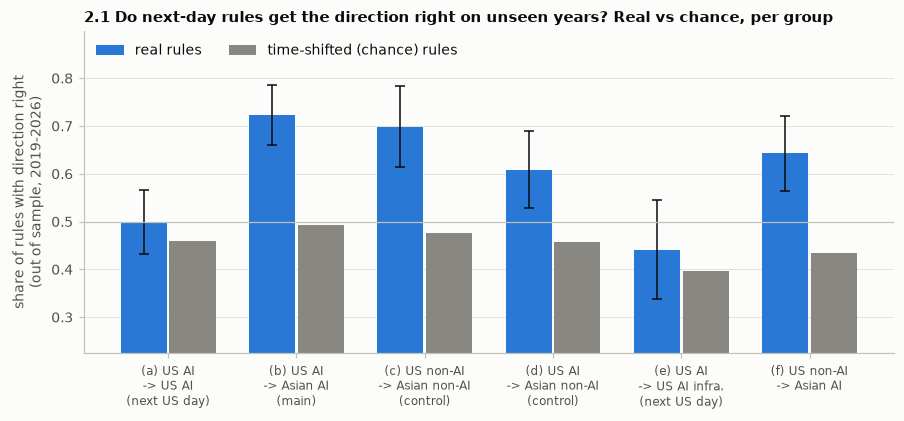

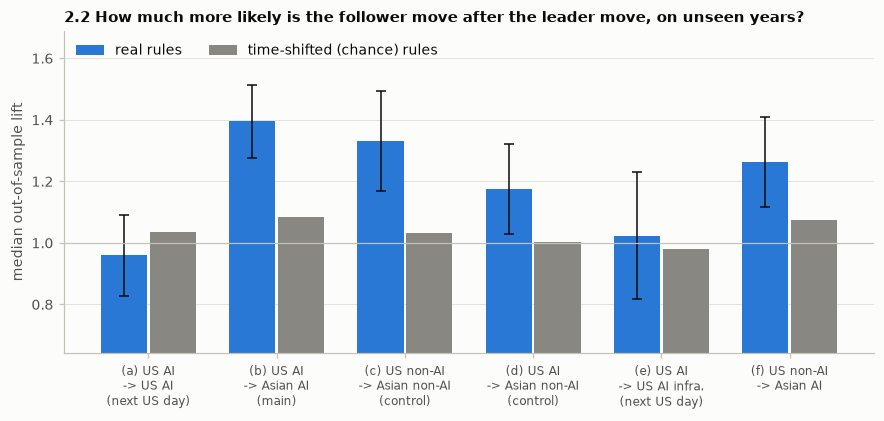

In [10]:
SHORT_LABEL = {"a": "(a) US AI\n-> US AI\n(next US day)", "b": "(b) US AI\n-> Asian AI\n(main)",
               "c": "(c) US non-AI\n-> Asian non-AI\n(control)", "d": "(d) US AI\n-> Asian non-AI\n(control)",
               "e": "(e) US AI\n-> US AI infra.\n(next US day)", "f": "(f) US non-AI\n-> Asian AI"}


def comparison_figure(table, column_real, column_null, ci_column, ylabel, title, name, ref=None):
    # Real vs null per group on one axis; the real bar carries the bootstrap interval of its excess over null.
    order = [i for i in table.index]
    x = np.arange(len(order))
    fig, ax = plt.subplots(figsize=(9.5, 3.8))
    width = 0.36
    real = table[column_real].astype(float).to_numpy()
    null = table[column_null].astype(float).to_numpy()
    lo = np.array([c[0] for c in table[ci_column]]) + null
    hi = np.array([c[1] for c in table[ci_column]]) + null
    ax.bar(x - width / 2 - 0.01, real, width, color=REAL, label="real rules")
    ax.bar(x + width / 2 + 0.01, null, width, color=NULL, label="time-shifted (chance) rules")
    ax.errorbar(x - width / 2 - 0.01, real, yerr=[real - lo, hi - real], fmt="none", ecolor=INK, lw=1, capsize=3)
    if ref is not None:
        ax.axhline(ref, color=AXIS, lw=0.8)
    lo_y = min(np.nanmin(real), np.nanmin(null), np.nanmin(lo))
    hi_y = max(np.nanmax(real), np.nanmax(null), np.nanmax(hi))
    pad = (hi_y - lo_y) * 0.25
    ax.set_ylim(max(0, lo_y - pad) if ref is None else min(ref, lo_y) - pad, hi_y + pad)
    ax.set_xticks(x, [SHORT_LABEL[i[1]] for i in order], fontsize=8)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y")
    ax.set_title(title)
    ax.legend(loc="upper left", frameon=False, ncol=2, bbox_to_anchor=(0, 1.0))
    save(fig, name)
    plt.show()


comparison_figure(main_table, "direction right (real)", "direction right (null)", "excess 95% CI",
                  "share of rules with direction right\n(out of sample, 2019-2026)",
                  "2.1 Do next-day rules get the direction right on unseen years? Real vs chance, per group",
                  "s2_1_direction_right_by_group", ref=0.5)
comparison_figure(main_table, "median test lift (real)", "median test lift (null)", "lift excess 95% CI",
                  "median out-of-sample lift",
                  "2.2 How much more likely is the follower move after the leader move, on unseen years?",
                  "s2_2_test_lift_by_group", ref=1.0)

### 2.3 The excess year by year (main groups)

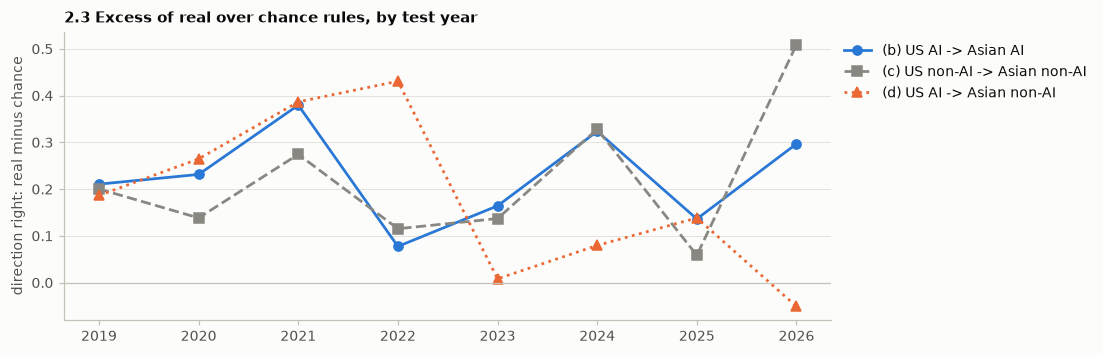

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.4))
styles = {"b": (REAL, "-", "o"), "c": (MUTED, "--", "s"), "d": (ASIA_COLOR, ":", "^")}
for g, (color, ls, marker) in styles.items():
    d = yearly[yearly["group"] == g].set_index("test year")
    ex = d["direction right (real)"] - d["direction right (null)"]
    ax.plot(ex.index, ex.values, color=color, ls=ls, marker=marker, markersize=6, label=f"({g}) {GROUP_LABEL[g]}")
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_ylabel("direction right: real minus chance")
ax.set_title("2.3 Excess of real over chance rules, by test year")
ax.grid(axis="y")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
save(fig, "s2_3_excess_by_year")
plt.show()

### 2.4 Direction or volatility clustering?

A rule whose mirror also has test lift above 1 says only "a big move follows a big move", in either direction.
We split the scored real rules into: **direction** (own lift > 1 and > mirror), **volatility only** (both > 1 but
mirror at least as high), and **fails** (own lift <= 1).

In [12]:
def classify(df):
    s = df[df["scored"]]
    direction = (s["test_lift"] > 1) & (s["test_lift"] > s["test_mirror_lift"])
    vol = (s["test_lift"] > 1) & (s["test_mirror_lift"] > 1) & ~direction
    return {"scored": len(s), "direction": float(direction.mean()), "volatility only": float(vol.mean()),
            "fails": float((s["test_lift"] <= 1).mean())}


kinds = []
for g, res in RESULTS.items():
    r, n = pooled(res["real"].values()), pooled(res["null"].values())
    if len(r):
        kinds.append({"group": f"({g}) {GROUP_LABEL[g]}", "rules": "real", **classify(r)})
    if len(n):
        kinds.append({"group": f"({g}) {GROUP_LABEL[g]}", "rules": "chance (time-shifted)", **classify(n)})
kinds = pd.DataFrame(kinds).set_index(["group", "rules"])
kinds.to_csv(OUT_DIR / "s2_direction_vs_volatility.csv")
KEY["direction_vs_volatility"] = {f"{g} | {k}": v for (g, k), v in kinds.round(4).to_dict(orient="index").items()}
kinds.round(3)

scored  \
group                                           rules                           
(a) US AI -> US AI (next US day)                real                      160   
                                                chance (time-shifted)     307   
(b) US AI -> Asian AI                           real                      700   
                                                chance (time-shifted)     974   
(c) US non-AI -> Asian non-AI                   real                      126   
                                                chance (time-shifted)     233   
(d) US AI -> Asian non-AI                       real                      138   
                                                chance (time-shifted)     370   
(e) US AI -> US AI infrastructure (next US day) real                       68   
                                                chance (time-shifted)     161   
(f) US non-AI -> Asian AI                       real                      386   
                                                chance (time-shifted)     575   

                                                                       direction  \
group                                           rules                              
(a) US AI -> US AI (next US day)                real                       0.350   
                                                chance (time-shifted)      0.384   
(b) US AI -> Asian AI                           real                       0.641   
                                                chance (time-shifted)      0.433   
(c) US non-AI -> Asian non-AI                   real                       0.611   
                                                chance (time-shifted)      0.403   
(d) US AI -> Asian non-AI                       real                       0.507   
                                                chance (time-shifted)      0.357   
(e) US AI -> US AI infrastructure (next US day) real                       0.324   
                                                chance (time-shifted)      0.342   
(f) US non-AI -> Asian AI                       real                       0.588   
                                                chance (time-shifted)      0.383   

                                                                       volatility only  \
group                                           rules                                    
(a) US AI -> US AI (next US day)                real                             0.119   
                                                chance (time-shifted)            0.150   
(b) US AI -> Asian AI                           real                             0.080   
                                                chance (time-shifted)            0.125   
(c) US non-AI -> Asian non-AI                   real                             0.095   
                                                chance (time-shifted)            0.120   
(d) US AI -> Asian non-AI                       real                             0.065   
                                                chance (time-shifted)            0.146   
(e) US AI -> US AI infrastructure (next US day) real                             0.176   
                                                chance (time-shifted)            0.130   
(f) US non-AI -> Asian AI                       real                             0.083   
                                                chance (time-shifted)            0.155   

                                                                       fails  
group                                           rules                         
(a) US AI -> US AI (next US day)                real                   0.531  
                                                chance (time-shifted)  0.466  
(b) US AI -> Asian AI                           real                   0.279  
                                                chance (time-shifted)  0.441  
(c) US non-AI -> Asian n

### 2.5 Do two-item antecedents add anything? (the "why association rules, not correlation" test)

For each scored rule with two leader items, compare its test lift with the better of its two one-item versions on
the same test days. If pairs rarely win, combinations carry no extra information and a correlation would do.

In [13]:
pair_rows = []
for g, res in RESULTS.items():
    basket = GROUPS[g][1]
    for Y in TEST_YEARS:
        r = res["real"][Y]
        if len(r) == 0:
            continue
        pairs = r[r["scored"] & (r["n_ante_items"] == 2)]
        te = basket.loc[test_rows(Y)]
        for _, rule in pairs.iterrows():
            singles = single_part_test_lifts(rule, te)
            pair_rows.append({"group": g, "year": Y, "rule": rule["rule"], "pair test lift": rule["test_lift"],
                              "best single test lift": np.nanmax(singles)})
pair_df = pd.DataFrame(pair_rows)
pair_summary = (pair_df.assign(pair_wins=pair_df["pair test lift"] > pair_df["best single test lift"])
                .groupby("group").agg(two_item_rules=("rule", "size"), pair_wins=("pair_wins", "mean"))
                if len(pair_df) else pd.DataFrame())
pair_summary.index = [f"({g}) {GROUP_LABEL[g]}" for g in pair_summary.index]
pair_summary.to_csv(OUT_DIR / "s2_pair_vs_single.csv")
KEY["pair_vs_single"] = pair_summary.round(4).to_dict(orient="index")
pair_summary.round(3)

,two_item_rules,pair_wins
(a) US AI -> US AI (next US day),5,0.200
(b) US AI -> Asian AI,37,0.432
(c) US non-AI -> Asian non-AI,1,1.000
(d) US AI -> Asian non-AI,1,0.000
(e) US AI -> US AI infrastructure (next US day),1,1.000
(f) US non-AI -> Asian AI,17,0.176


### 2.6 Robustness of the main comparison

The pre-registered comparison, rerun with other thresholds, rarer moves (Z_K = 1.5) and follower items built
from residuals against an ex-stock home index, r_ex = (r_index - w x r_stock) / (1 - w), with the approximate
constant weights w in `data/universe.csv` (^TOPX is not on Yahoo Finance, so Japan uses ^N225 ex-stock).

In [14]:
def robustness_row(label, z_k, sup, conf, kind):
    groups = GROUPS if (z_k, kind) == (Z_K, "raw") else build_groups(z_k, kind)
    groups = {g: groups[g] for g in ["b", "c", "d"]}
    res = {g: cached(f"wf_rob_{g}_{z_k}_{sup}_{conf}_{kind}",
                     lambda b=b, g=g: walk_forward(b, sup, conf, SEED + ord(g)))
           for g, (_, b) in groups.items()}
    table, diffs = excess_table(res, groups, N_BOOT // 2, SEED)
    dec = decision(table.rename(index=lambda g: f"({g})"), diffs)
    ci = lambda v: f"[{v[0]:+.3f}, {v[1]:+.3f}]"
    return {"setting": label,
            "scored rules b / c / d": " / ".join(str(int(table.loc[g, "scored rules (real)"])) for g in "bcd"),
            "excess b": table.loc["b", "excess"], "excess b CI": ci(table.loc["b", "excess 95% CI"]),
            "excess c": table.loc["c", "excess"], "excess d": table.loc["d", "excess"],
            "b - c": diffs["excess(b) - excess(c)"]["estimate"], "b - c CI": ci(diffs["excess(b) - excess(c)"]["95% CI"]),
            "b - d": diffs["excess(b) - excess(d)"]["estimate"], "b - d CI": ci(diffs["excess(b) - excess(d)"]["95% CI"]),
            "verdict": dec["verdict"]}


robust = pd.DataFrame([robustness_row(*s) for s in ROBUSTNESS]).set_index("setting")
robust.to_csv(OUT_DIR / "s2_robustness.csv")
KEY["robustness"] = robust.round(4).to_dict(orient="index")
print(f"robustness done at {time.time() - T0:.0f} s")
robust.round(3)

robustness done at 53 s


,scored rules b / c / d,excess b,excess b CI,excess c,excess d,b - c,b - c CI,b - d,b - d CI,verdict
setting,,,,,,,,,,
"main: Z 1.0, sup 0.02, conf 0.20, raw",700 / 126 / 138,0.229,"[+0.167, +0.291]",0.222,0.152,0.007,"[-0.094, +0.108]",0.077,"[-0.019, +0.173]",market-wide transmission (not AI-specific)
"Z 1.0, sup 0.03, conf 0.20",250 / 54 / 28,0.214,"[+0.120, +0.307]",0.291,0.286,-0.077,"[-0.236, +0.081]",-0.072,"[-0.277, +0.133]",market-wide transmission (not AI-specific)
"Z 1.0, sup 0.015, conf 0.15",1388 / 301 / 384,0.169,"[+0.121, +0.216]",0.119,0.135,0.050,"[-0.017, +0.117]",0.034,"[-0.038, +0.105]",market-wide transmission (not AI-specific)
"Z 1.5, sup 0.008, conf 0.12",400 / 125 / 93,0.121,"[+0.075, +0.166]",0.148,0.025,-0.027,"[-0.118, +0.064]",0.096,"[-0.003, +0.194]",market-wide transmission (not AI-specific)
"Z 1.5, sup 0.005, conf 0.10",1208 / 313 / 365,0.086,"[+0.054, +0.119]",0.072,0.029,0.015,"[-0.030, +0.059]",0.058,"[+0.013, +0.103]",market-wide transmission (not AI-specific)
ex-stock home-index residual followers,375 / 103 / 143,0.241,"[+0.189, +0.292]",0.286,0.166,-0.045,"[-0.158, +0.068]",0.075,"[-0.030, +0.180]",market-wide transmission (not AI-specific)


### 2.7 Which leader -> follower links hold up?

An edge is one US leader -> one Asian follower with a given direction relation (same / opposite). It "holds" in a
test year if a one-item rule for that edge was mined on the previous three years and, on the test year, has test
lift > 1 and beats its mirror. We keep edges that held in at least 3 test years **and** whose hold rate (years held
/ years scored) beats the hold rate of the time-shifted chance rules. Only group (b).

In [15]:
def edge_table(res):
    def edges(df):
        s = df[df["scored"] & (df["n_ante_items"] == 1)].copy()
        if s.empty:
            return s
        s["leader"] = s["antecedent"].str[0].map(ticker_of)
        s["follower"] = s["consequent"].map(ticker_of)
        s["relation"] = np.where(s["antecedent"].str[0].map(direction_of) == s["consequent"].map(direction_of),
                                 "same", "opposite")
        s["held"] = (s["test_lift"] > 1) & s["direction_right"]
        return s
    real = edges(pooled(res["real"].values()))
    null = edges(pooled(res["null"].values()))
    null_rate = float(null["held"].mean()) if len(null) else np.nan
    per_year = real.groupby(["leader", "follower", "relation", "year"]).agg(held=("held", "max"),
                                                                            lift=("test_lift", "mean"))
    e = per_year.groupby(["leader", "follower", "relation"]).agg(years_scored=("held", "size"),
                                                                 years_held=("held", "sum"),
                                                                 mean_test_lift=("lift", "mean")).reset_index()
    e["hold rate"] = e["years_held"] / e["years_scored"]
    e["kept"] = (e["years_held"] >= NETWORK_MIN_YEARS) & (e["hold rate"] > null_rate)
    return e.sort_values(["kept", "years_held", "mean_test_lift"], ascending=False), null_rate


# Known economic links (public company information; "peer" = same product market, not a supply relation).
LINKS = {
    ("NVDA", "2330.TW"): "TSMC manufactures Nvidia's GPUs", ("AMD", "2330.TW"): "TSMC manufactures AMD's chips",
    ("AVGO", "2330.TW"): "TSMC manufactures Broadcom's custom AI chips",
    ("NVDA", "000660.KS"): "SK hynix supplies HBM memory for Nvidia GPUs",
    ("NVDA", "042700.KS"): "Hanmi makes HBM bonding tools (via SK hynix)",
    ("NVDA", "6857.T"): "Advantest supplies GPU/HBM test equipment",
    ("NVDA", "2382.TW"): "Quanta assembles Nvidia AI servers", ("NVDA", "2317.TW"): "Foxconn assembles Nvidia AI servers",
    ("NVDA", "3231.TW"): "Wistron makes Nvidia GPU boards", ("NVDA", "6669.TW"): "Wiwynn builds AI servers",
    ("NVDA", "3711.TW"): "ASE packages and tests chips", ("NVDA", "2308.TW"): "Delta supplies data-centre power",
    ("MU", "000660.KS"): "memory peer (DRAM/HBM)", ("MU", "005930.KS"): "memory peer (DRAM/HBM)",
    ("MSFT", "6669.TW"): "Wiwynn builds servers for hyperscalers", ("META", "6669.TW"): "Wiwynn builds servers for hyperscalers",
    ("MSFT", "2382.TW"): "Quanta builds servers for hyperscalers", ("META", "2382.TW"): "Quanta builds servers for hyperscalers",
    ("AMZN", "2382.TW"): "Quanta builds servers for hyperscalers", ("GOOGL", "2382.TW"): "Quanta builds servers for hyperscalers",
    ("AVGO", "2454.TW"): "chip-design peer", ("AMD", "2454.TW"): "chip-design peer",
}

CHIPMAKERS = {"NVDA", "AMD", "AVGO", "MU"}
EQUIPMENT = {"8035.T": "chip-equipment maker", "6857.T": "chip-test equipment maker",
             "6146.T": "wafer dicing/grinding tool maker", "6920.T": "mask-inspection equipment maker"}


def interpret(leader, follower):
    # A direct company link if we know one, otherwise the sector link (or none).
    if (leader, follower) in LINKS:
        return LINKS[(leader, follower)]
    if follower in EQUIPMENT and leader in CHIPMAKERS:
        return f"sector: {EQUIPMENT[follower]}, demand follows chipmakers' spending"
    if follower in EQUIPMENT:
        return f"sector: {EQUIPMENT[follower]}, demand follows AI capex"
    if leader in CHIPMAKERS and follower in {"2330.TW", "005930.KS", "000660.KS", "2454.TW", "3711.TW"}:
        return "semiconductor sector peer"
    return "no specific link known"


edges_b, null_hold_rate = edge_table(RESULTS["b"])
edges_b["leader name"] = edges_b["leader"].map(NAME)
edges_b["follower name"] = edges_b["follower"].map(NAME)
edges_b["known link"] = [interpret(l, f) for l, f in zip(edges_b["leader"], edges_b["follower"])]
edges_b.to_csv(OUT_DIR / "s2_edges_b.csv", index=False)
kept = edges_b[edges_b["kept"]]
KEY["edges_b"] = {"null_hold_rate": null_hold_rate, "n_edges_scored": int(len(edges_b)), "n_kept": int(len(kept)),
                  "kept": kept[["leader", "follower", "relation", "years_held", "years_scored",
                                "mean_test_lift", "known link"]].round(3).to_dict(orient="records")}
print(f"{len(edges_b)} edges were scored in at least one test year; null hold rate {null_hold_rate:.3f}; "
      f"{len(kept)} edges kept")
cols = ["leader name", "follower name", "relation", "years_held", "years_scored", "hold rate", "mean_test_lift",
        "known link"]
(kept if len(kept) else edges_b.head(10))[cols].round(3)

162 edges were scored in at least one test year; null hold rate 0.432; 45 edges kept


,leader name,follower name,relation,years_held,years_scored,hold rate,mean_test_lift,known link
13,AMD,Tokyo Electron,same,8,8,1.000,2.122,"sector: chip-equipment maker, demand follows c..."
104,Micron,SK hynix,same,8,8,1.000,1.966,memory peer (DRAM/HBM)
120,Micron,Tokyo Electron,same,8,8,1.000,1.921,"sector: chip-equipment maker, demand follows c..."
133,Nvidia,Advantest,same,8,8,1.000,1.788,Advantest supplies GPU/HBM test equipment
115,Micron,Disco,same,8,8,1.000,1.777,"sector: wafer dicing/grinding tool maker, dema..."
131,Nvidia,Disco,same,8,8,1.000,1.685,"sector: wafer dicing/grinding tool maker, dema..."
50,Broadcom,Advantest,same,8,8,1.000,1.622,"sector: chip-test equipment maker, demand foll..."
109,Micron,TSMC,same,7,7,1.000,1.979,semiconductor sector peer
9,AMD,Disco,same,7,8,0.875,1.921,"sector: wafer dicing/grinding tool maker, dema..."
11,AMD,Advantest,same,7,8,0.875,1.855,"sector: chip-test equipment maker, demand foll..."


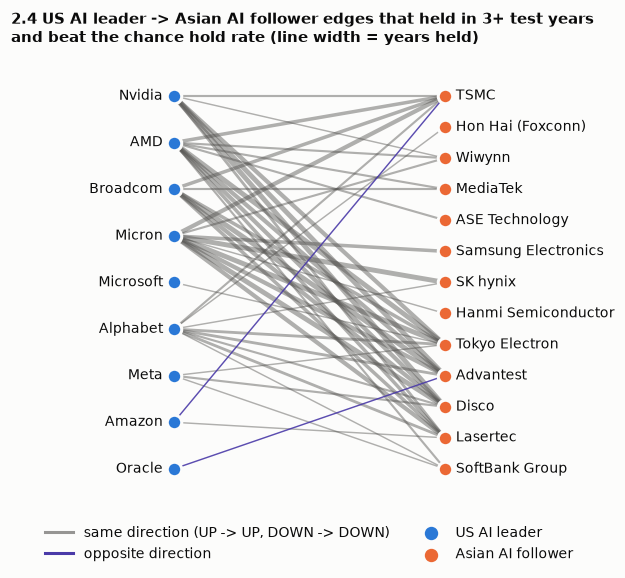

In [16]:
def draw_network(e, title, name):
    # Bipartite picture: US leaders on the left, Asian followers on the right; line width = years held.
    if e.empty:
        print("no edge passes the filter; nothing to draw")
        return
    leaders = sorted(e["leader"].unique(), key=US_AI.index)
    followers = sorted(e["follower"].unique(), key=ASIA_AI.index)
    yl = dict(zip(leaders, np.linspace(1, 0, len(leaders)) if len(leaders) > 1 else [0.5]))
    yf = dict(zip(followers, np.linspace(1, 0, len(followers)) if len(followers) > 1 else [0.5]))
    fig, ax = plt.subplots(figsize=(7, max(2.6, 0.42 * max(len(leaders), len(followers)))))
    for _, r in e.iterrows():
        same = r["relation"] == "same"
        ax.plot([0, 1], [yl[r["leader"]], yf[r["follower"]]], color=SAME_EDGE if same else OPPOSITE_EDGE,
                lw=0.5 + 0.45 * (r["years_held"] - NETWORK_MIN_YEARS + 1), alpha=0.45 if same else 0.9,
                solid_capstyle="round", zorder=1 if same else 2)
    for t, y in yl.items():
        ax.scatter([0], [y], s=90, color=US_COLOR, edgecolor=SURFACE, linewidth=2, zorder=3)
        ax.text(-0.04, y, NAME[t], ha="right", va="center")
    for t, y in yf.items():
        ax.scatter([1], [y], s=90, color=ASIA_COLOR, edgecolor=SURFACE, linewidth=2, zorder=3)
        ax.text(1.04, y, NAME[t], ha="left", va="center")
    ax.plot([], [], color=SAME_EDGE, lw=2, alpha=0.6, label="same direction (UP -> UP, DOWN -> DOWN)")
    ax.plot([], [], color=OPPOSITE_EDGE, lw=2, label="opposite direction")
    ax.scatter([], [], s=60, color=US_COLOR, label="US AI leader")
    ax.scatter([], [], s=60, color=ASIA_COLOR, label="Asian AI follower")
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(-0.12, 1.12)
    ax.axis("off")
    ax.set_title(title)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2)
    save(fig, name)
    plt.show()


draw_network(kept, f"2.4 US AI leader -> Asian AI follower edges that held in {NETWORK_MIN_YEARS}+ test years\n"
             "and beat the chance hold rate (line width = years held)", "s2_4_network_b")

## What Stage 2 shows

The numbers below are printed from this run (`KEY`), so the text and the results cannot drift apart.

In [17]:
mc = KEY["main_comparison"]["groups"]
lab = {g: f"({g}) {GROUP_LABEL[g]}" for g in GROUP_LABEL}
print(f"Pre-registered verdict: {KEY['decision']['verdict']}  {KEY['decision']}")
for g in "abcdef":
    r = mc[lab[g]]
    print(f"  {lab[g]:47s} direction right {r['direction right (real)']:.1%} vs chance "
          f"{r['direction right (null)']:.1%}  (excess {r['excess']:+.3f}, 95% CI {fmt_ci(r['excess 95% CI'])}); "
          f"median test lift {r['median test lift (real)']:.2f} vs {r['median test lift (null)']:.2f}")
for k, v in KEY["main_comparison"]["differences"].items():
    print(f"  {k}: {v['estimate']:+.3f}, 95% CI {fmt_ci(v['95% CI'])}")
print(f"Robustness: verdict per setting: {robust['verdict'].value_counts().to_dict()}")
print(f"Edges (b): {KEY['edges_b']['n_kept']} of {KEY['edges_b']['n_edges_scored']} held in "
      f"{NETWORK_MIN_YEARS}+ test years above the chance hold rate ({KEY['edges_b']['null_hold_rate']:.1%}); "
      f"{sum(e['relation'] == 'same' for e in KEY['edges_b']['kept'])} of them same-direction")

Pre-registered verdict: market-wide transmission (not AI-specific)  {'1: excess(b) > 0': True, '2: b beats c': False, '3: b beats d': False, 'verdict': 'market-wide transmission (not AI-specific)'}
  (a) US AI -> US AI (next US day)                direction right 50.0% vs chance 45.9%  (excess +0.041, 95% CI [-0.026, +0.108]); median test lift 0.96 vs 1.03
  (b) US AI -> Asian AI                           direction right 72.3% vs chance 49.4%  (excess +0.229, 95% CI [+0.166, +0.292]); median test lift 1.39 vs 1.09
  (c) US non-AI -> Asian non-AI                   direction right 69.8% vs chance 47.6%  (excess +0.222, 95% CI [+0.138, +0.306]); median test lift 1.33 vs 1.03
  (d) US AI -> Asian non-AI                       direction right 60.9% vs chance 45.7%  (excess +0.152, 95% CI [+0.071, +0.233]); median test lift 1.17 vs 1.00
  (e) US AI -> US AI infrastructure (next US day) direction right 44.1% vs chance 39.8%  (excess +0.044, 95% CI [-0.060, +0.148]); median test lift 1.02 vs 0.

**Reading the results (numbers in the cell above).**
* **The time gap matters.** Next-day rules from US leaders to Asian stocks beat chance clearly on unseen years:
  far more of them get the direction right than time-shifted chance rules, and many pass Benjamini-Hochberg
  in sample while chance rules almost never do. The same method between US stocks (groups a and e) is at chance
  level, as in our earlier notebook. Information from the US session shows up in Asia the next morning, because
  Asia was closed when it arrived.
* **But it is not AI-specific.** By the pre-registered rule, US AI -> Asian AI does not beat the non-AI controls:
  US non-AI -> Asian non-AI works about as well, and US AI -> Asian non-AI only somewhat less well, with
  intervals that overlap. The verdict is the same in every robustness setting, including residuals against an
  ex-stock home index. So what we mine is mostly market-wide (and sector) transmission across the time zones.
* **Where AI does show up is in which links last.** The edges that hold in many test years run mostly from US
  chipmakers (Nvidia, AMD, Broadcom, Micron) to Japanese chip-equipment makers (Tokyo Electron, Advantest, Disco,
  Lasertec) and memory peers (SK hynix, Samsung), almost all same-direction. Hyperscalers (Microsoft, Meta,
  Amazon, Oracle) have few lasting links. This is a semiconductor-sector link, not a specific supplier contract.
* **Two-item antecedents** rarely beat their better single item, so combinations add little beyond pairwise links.
* **Caveat for Stage 3:** these follower items are close-to-close, so they include the jump at the Asian open,
  which nobody can trade after seeing the US close. Stage 3 asks how much survives after the open.

# Stage 3. Tradeability: does any of it survive the Asian open?

The follower items so far are close-to-close (previous Asian close -> close on the follower date). That includes
the jump at the Asian open, which nobody can trade after seeing the US close. We split the follower day in two:
* **gap** = previous close -> open (happens before anyone in Asia can trade on the US news),
* **oc** = open -> close (the part you could still trade after seeing the US close).

**3.1** scores every rule from Stage 2 (mined on close-to-close items) again on the test years, with the same
follower move defined from gap returns and from oc returns. Nothing is re-mined, so the only change is which part
of the follower day counts. The chance rules get the same treatment.

In [18]:
def asian_returns(tickers, kind="cc"):
    # Close-to-close (cc), open-to-close (oc) or overnight gap (previous close -> open), each on its own calendar.
    out = []
    for market in ["JP", "KR", "TW"]:
        ts = [t for t in tickers if MARKET_OF[t] == market]
        if ts:
            cc, oc, gap = local_returns(CLOSE, OPEN, ts, market_calendar(market))
            out.append((market, {"cc": cc, "oc": oc, "gap": gap}[kind]))
    return out


def asian_baskets(kind, z_k=Z_K, leaders=None):
    # Extended baskets for the cross-market groups with follower items from `kind` returns (same leader items).
    leaders = leaders or {"ai": us_residual_items(US_AI, z_k), "ctrl": us_residual_items(US_CTRL, z_k)}
    f_ai = follower_items(asian_returns(ASIA_AI, kind), z_k).reindex(ROWS).fillna(False).astype(bool)
    f_ctrl = follower_items(asian_returns(ASIA_CTRL, kind), z_k).reindex(ROWS).fillna(False).astype(bool)
    lead = {k: v.reindex(ROWS).fillna(False).astype(bool) for k, v in leaders.items()}
    spec = {"b": ("ai", f_ai), "c": ("ctrl", f_ctrl), "d": ("ai", f_ctrl), "f": ("ctrl", f_ai)}
    return {g: (GROUP_LABEL[g], extended_basket(lead[l], f)) for g, (l, f) in spec.items()}


def rescore(res, basket):
    # Score the same rules again on the test years, with follower items taken from another basket.
    out = {"real": {}, "null": {}, "m_total": res["m_total"]}
    for kind in ["real", "null"]:
        for Y in TEST_YEARS:
            df = res[kind][Y]
            if len(df) == 0:
                out[kind][Y] = df
                continue
            base = df[df["scored"]][["antecedent", "consequent", "rule", "n_ante_items", "year"]
                                    + (["copy"] if "copy" in df else [])].reset_index(drop=True)
            out[kind][Y] = evaluate_out_of_sample(base, basket.loc[test_rows(Y)], MIN_FIRED_TEST)
    return out


TRADE_GROUPS = ["b", "c", "d", "f"]
VARIANTS = {"cc": "close-to-close (Stage 2)", "gap": "gap: previous close -> open", "oc": "open -> close"}
trade_rows, TRADE = [], {}
for kind in VARIANTS:
    baskets = {g: GROUPS[g] for g in TRADE_GROUPS} if kind == "cc" else asian_baskets(kind)
    res = {g: RESULTS[g] if kind == "cc" else rescore(RESULTS[g], baskets[g][1]) for g in TRADE_GROUPS}
    table, _ = cached(f"excess_trade_{kind}", lambda res=res, baskets=baskets: excess_table(res, baskets, N_BOOT, SEED, pairs=()))
    TRADE[kind] = table
    for g in TRADE_GROUPS:
        r = table.loc[g]
        trade_rows.append({"group": f"({g}) {GROUP_LABEL[g]}", "follower return": VARIANTS[kind],
                           "scored rules": int(r["scored rules (real)"]),
                           "direction right (real)": r["direction right (real)"],
                           "direction right (chance)": r["direction right (null)"], "excess": r["excess"],
                           "excess 95% CI": fmt_ci(r["excess 95% CI"]),
                           "median test lift (real)": r["median test lift (real)"],
                           "median test lift (chance)": r["median test lift (null)"]})
trade_table = pd.DataFrame(trade_rows).set_index(["group", "follower return"])
trade_table.to_csv(OUT_DIR / "s3_tradeability.csv")
survival = {g: {"excess_cc": TRADE["cc"].loc[g, "excess"], "excess_gap": TRADE["gap"].loc[g, "excess"],
                "excess_oc": TRADE["oc"].loc[g, "excess"],
                "lift_excess_cc": TRADE["cc"].loc[g, "lift excess"], "lift_excess_oc": TRADE["oc"].loc[g, "lift excess"]}
            for g in TRADE_GROUPS}
KEY["tradeability"] = {"table": {f"{g} | {k}": v for (g, k), v in trade_table.round(4).to_dict(orient="index").items()},
                       "survival": survival}
trade_table.round(3)

,,scored rules,direction right (real),direction right (chance),excess,excess 95% CI,median test lift (real),median test lift (chance)
group,follower return,,,,,,,
(b) US AI -> Asian AI,close-to-close (Stage 2),700,0.723,0.494,0.229,"[+0.166, +0.292]",1.395,1.086
(c) US non-AI -> Asian non-AI,close-to-close (Stage 2),126,0.698,0.476,0.222,"[+0.138, +0.306]",1.331,1.031
(d) US AI -> Asian non-AI,close-to-close (Stage 2),138,0.609,0.457,0.152,"[+0.071, +0.233]",1.174,1.004
(f) US non-AI -> Asian AI,close-to-close (Stage 2),386,0.642,0.435,0.208,"[+0.129, +0.286]",1.262,1.074
(b) US AI -> Asian AI,gap: previous close -> open,700,0.720,0.501,0.219,"[+0.151, +0.287]",1.454,1.139
(c) US non-AI -> Asian non-AI,gap: previous close -> open,126,0.722,0.498,0.224,"[+0.141, +0.308]",1.375,1.082
(d) US AI -> Asian non-AI,gap: previous close -> open,138,0.688,0.535,0.153,"[+0.075, +0.232]",1.289,1.058
(f) US non-AI -> Asian AI,gap: previous close -> open,386,0.666,0.449,0.217,"[+0.135, +0.299]",1.439,1.100
(b) US AI -> Asian AI,open -> close,700,0.566,0.482,0.084,"[+0.037, +0.132]",1.125,1.045


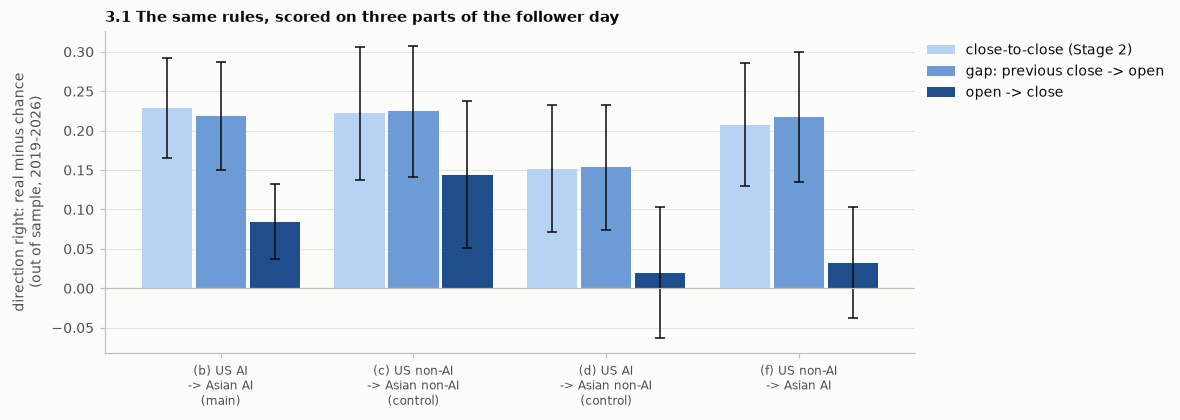

In [19]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
x = np.arange(len(TRADE_GROUPS))
width = 0.26
shades = {"cc": "#b7d3f4", "gap": "#6d9bd6", "oc": "#1f4e8c"}          # one hue, light -> dark (baseline ramp)
for i, kind in enumerate(VARIANTS):
    t = TRADE[kind].loc[TRADE_GROUPS]
    ex = t["excess"].astype(float).to_numpy()
    ci = np.array([list(c) for c in t["excess 95% CI"]])
    pos = x + (i - 1) * (width + 0.02)
    ax.bar(pos, ex, width, color=shades[kind], label=VARIANTS[kind])
    ax.errorbar(pos, ex, yerr=[ex - ci[:, 0], ci[:, 1] - ex], fmt="none", ecolor=INK, lw=1, capsize=3)
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xticks(x, [SHORT_LABEL[g] for g in TRADE_GROUPS], fontsize=8)
ax.set_ylabel("direction right: real minus chance\n(out of sample, 2019-2026)")
ax.set_title("3.1 The same rules, scored on three parts of the follower day")
ax.grid(axis="y")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
save(fig, "s3_1_tradeability")
plt.show()

## 3.2 A hypothesis suggested by Stage 1: does the opening gap partly reverse during the Asian day?

**Exploratory, not pre-registered.** The dataset sanity checks (Stage 1) showed that the Asian stocks'
open-to-close return on the follower date is slightly *negatively* correlated with SPY on US date *t*, while the
overnight gap is strongly positively correlated. That suggests the opening overreacts to the US session and
partly reverses. We found this by looking at the data, so the test below is a check, not a confirmation.

**3.2.1 Rules.** Mine next-day rules with follower items from **open-to-close** returns, keep only rules whose
consequent goes the **opposite** way to the leader items (e.g. `SPY_UP -> 2330.TW_DOWN+1`), and test them like
everything else: walk-forward, time-shifted chance rules, direction check (here the mirror is the same-direction
rule). Because Stage 1 was about the market, we add SPY itself as a leader (SPY_UP / SPY_DOWN: a SPY move of at
least 1 x its typical move).

In [20]:
def spy_items(z_k):
    # Market moves as items: SPY return vs its own typical move (no residual: this IS the market).
    cc = local_returns(CLOSE, OPEN, ["SPY"], US_DAYS)[0]
    return move_items(zscores(cc, VOL_WINDOW), z_k)


def opposite_only(rules):
    # Keep rules whose leader items all share one direction and whose follower item goes the other way.
    lead_dirs = rules["antecedent"].map(lambda a: {direction_of(i) for i in a})
    cons_dir = rules["consequent"].map(direction_of)
    return np.array([len(d) == 1 and c not in d for d, c in zip(lead_dirs, cons_dir)])


lead_rev = {"spy": spy_items(Z_K), "ai": us_residual_items(US_AI, Z_K), "ctrl": us_residual_items(US_CTRL, Z_K)}
f_oc_ai = follower_items(asian_returns(ASIA_AI, "oc"), Z_K)
f_oc_ctrl = follower_items(asian_returns(ASIA_CTRL, "oc"), Z_K)
on = lambda df: df.reindex(ROWS).fillna(False).astype(bool)
REV_GROUPS = {
    "r1": ("SPY -> Asian AI (oc)", extended_basket(on(lead_rev["spy"]), on(f_oc_ai))),
    "r2": ("SPY -> Asian non-AI (oc)", extended_basket(on(lead_rev["spy"]), on(f_oc_ctrl))),
    "r3": ("US AI -> Asian AI (oc)", extended_basket(on(lead_rev["ai"]), on(f_oc_ai))),
    "r4": ("US non-AI -> Asian non-AI (oc)", extended_basket(on(lead_rev["ctrl"]), on(f_oc_ctrl))),
}
REV_RESULTS = {g: cached(f"wf_rev_{g}", lambda b=b, g=g: walk_forward(b, MIN_SUPPORT, MIN_CONFIDENCE,
                                                                     SEED + 100 + int(g[1]), keep=opposite_only))
               for g, (_, b) in REV_GROUPS.items()}
rev_table, _ = cached("excess_rev", lambda: excess_table(REV_RESULTS, REV_GROUPS, N_BOOT, SEED, pairs=()))
rev_table.index = [f"({g}) {REV_GROUPS[g][0]}" for g in rev_table.index]
rev_show = rev_table[["scored rules (real)", "scored rules (null, per copy)", "direction right (real)",
                      "direction right (real) 95% CI", "direction right (null)", "excess", "excess 95% CI",
                      "median test lift (real)", "median test lift (null)"]].copy()
for c in ["excess 95% CI", "direction right (real) 95% CI"]:
    rev_show[c] = rev_show[c].map(lambda v: fmt_ci(v) if isinstance(v, tuple) else v)
rev_show.to_csv(OUT_DIR / "s3_reversal_rules.csv")
KEY["reversal_rules"] = rev_show.round(4).to_dict(orient="index")
rev_show.round(3)

,scored rules (real),"scored rules (null, per copy)",direction right (real),direction right (real) 95% CI,direction right (null),excess,excess 95% CI,median test lift (real),median test lift (null)
(r1) SPY -> Asian AI (oc),70,9.6,0.8,"[+0.681, +0.919]",0.791667,0.008333,"[-0.127, +0.144]",1.457526,1.542181
(r2) SPY -> Asian non-AI (oc),22,3.6,0.681818,"[+0.488, +0.875]",0.666667,0.015152,"[-0.287, +0.317]",1.346032,1.411765
(r3) US AI -> Asian AI (oc),126,100.2,0.515873,"[+0.442, +0.590]",0.467066,0.048807,"[-0.029, +0.127]",1.072253,0.984211
(r4) US non-AI -> Asian non-AI (oc),39,23.2,0.641026,"[+0.531, +0.751]",0.448276,0.19275,"[+0.067, +0.319]",1.232955,0.998621


**How to read this table (two cautions).**
* For the SPY groups (r1, r2) the time-shifted chance rules are **not** a useful baseline. With only two leader
  items (SPY_UP, SPY_DOWN), the shifted copies mine essentially the same rules as the real data, and all of them
  are then scored on the same real test days, so they inherit the same real reversal (direction right is about
  the same for real and chance rules). The meaningful benchmark here is the direction check itself: without a
  reversal, an opposite-direction rule beats its same-direction mirror half of the time, so compare
  "direction right (real)" and its interval with 50%.
* For the residual leaders (r3, r4) an opposite-direction rule is usually **not** a gap reversal. The rules that
  recur in r4 (e.g. JNJ down -> Mitsubishi UFJ up, JPM up -> Takeda down) are sector rotation between defensive
  and cyclical stocks. Only r1 and r2 test the Stage 1 hypothesis, which was about the market move.

**3.2.2 Could it be a data artefact?** Three checks, per stock (Taiwan only at stock level, because the ^TWII
opening value is stale):
* how often the open equals the previous close (a stale or missing open would make oc = cc) and how often volume
  is zero;
* the correlation of SPY on *t* with the stock's open-to-close return on the follower date, on all days, without
  days on which the open equals the previous close, and without the 1% of days with the largest |gap|
  (so a handful of extreme days cannot drive it).

In [21]:
def follower_returns_on_rows(tickers):
    # cc, oc and gap returns of Asian stocks moved onto the US dates in ROWS.
    out = {}
    for kind in ["cc", "oc", "gap"]:
        frames = [follower_frame(r, calendar[calendar["market"] == m]) for m, r in asian_returns(tickers, kind)]
        out[kind] = pd.concat(frames, axis=1, sort=True).reindex(ROWS)
    return out


ASIA_ALL = ASIA_AI + ASIA_CTRL
FR = follower_returns_on_rows(ASIA_ALL)
SPY_RET = local_returns(CLOSE, OPEN, ["SPY"], US_DAYS)[0]["SPY"].reindex(ROWS)
open_is_prev_close = FR["gap"].abs() < 1e-9                       # open exactly at the previous close
VOLUME = wide(prices, "volume")

art = []
for t in ASIA_ALL:
    days = market_calendar(MARKET_OF[t])
    vol = VOLUME[t].reindex(days).dropna()
    oc, gap = FR["oc"][t], FR["gap"][t]
    ok = oc.notna() & gap.notna() & SPY_RET.notna()
    cut = gap.abs()[ok].quantile(0.99)
    art.append({"ticker": t, "name": NAME[t], "market": MARKET_OF[t],
                "group": "AI" if t in ASIA_AI else "non-AI",
                "open = previous close": float(open_is_prev_close[t][ok].mean()),
                "volume = 0": float((vol == 0).mean()),
                "corr(SPY, oc) all days": SPY_RET[ok].corr(oc[ok]),
                "without open = prev close": SPY_RET[ok & ~open_is_prev_close[t]].corr(oc[ok & ~open_is_prev_close[t]]),
                "without top 1% |gap|": SPY_RET[ok & (gap.abs() <= cut)].corr(oc[ok & (gap.abs() <= cut)]),
                "corr(SPY, gap)": SPY_RET[ok].corr(gap[ok])})
artefacts = pd.DataFrame(art).set_index("ticker")
artefacts.to_csv(OUT_DIR / "s3_reversal_artefact_checks.csv")
by_market = artefacts.groupby(["market", "group"])[["open = previous close", "volume = 0", "corr(SPY, oc) all days",
                                                    "without open = prev close", "without top 1% |gap|",
                                                    "corr(SPY, gap)"]].mean()
by_market["stocks with negative corr(SPY, oc)"] = artefacts.groupby(["market", "group"])["corr(SPY, oc) all days"].apply(
    lambda c: f"{(c < 0).sum()} of {len(c)}")
KEY["reversal_artefacts"] = {"per_ticker": artefacts.round(4).to_dict(orient="index"),
                             "by_market": {f"{m} | {g}": v for (m, g), v in by_market.round(4).to_dict(orient="index").items()}}
by_market.round(3)

open = previous close  volume = 0  corr(SPY, oc) all days  \
market group                                                               
JP     AI                      0.001       0.001                  -0.137   
       non-AI                  0.001       0.001                  -0.098   
KR     AI                      0.008       0.008                  -0.126   
       non-AI                  0.016       0.006                  -0.099   
TW     AI                      0.017       0.001                  -0.088   
       non-AI                  0.103       0.000                  -0.031   

               without open = prev close  without top 1% |gap|  \
market group                                                     
JP     AI                         -0.137                -0.122   
       non-AI                     -0.098                -0.085   
KR     AI                         -0.127                -0.124   
       non-AI                     -0.100                -0.095   
TW     AI                         -0.088                -0.074   
       non-AI                     -0.034                -0.007   

               corr(SPY, gap) stocks with negative corr(SPY, oc)  
market group                                                      
JP     AI               0.513                             5 of 5  
       non-AI           0.441                             3 of 3  
KR     AI               0.488                             3 of 3  
       non-AI           0.485                             1 of 1  
TW     AI               0.459                             8 of 8  
       non-AI           0.386                             1 of 2

In [22]:
artefacts.drop(columns=["name"]).round(3)

,market,group,open = previous close,volume = 0,"corr(SPY, oc) all days",without open = prev close,without top 1% |gap|,"corr(SPY, gap)"
ticker,,,,,,,,
2330.TW,TW,AI,0.012,0.000,-0.117,-0.117,-0.094,0.538
2317.TW,TW,AI,0.033,0.003,-0.086,-0.087,-0.063,0.482
2382.TW,TW,AI,0.019,0.000,-0.093,-0.093,-0.088,0.442
3231.TW,TW,AI,0.020,0.000,-0.085,-0.086,-0.080,0.447
6669.TW,TW,AI,0.005,0.001,-0.108,-0.108,-0.111,0.354
2308.TW,TW,AI,0.023,0.000,-0.061,-0.061,-0.041,0.465
2454.TW,TW,AI,0.008,0.001,-0.122,-0.121,-0.095,0.467
3711.TW,TW,AI,0.016,0.004,-0.034,-0.034,-0.024,0.477
005930.KS,KR,AI,0.006,0.006,-0.116,-0.116,-0.117,0.457


**3.2.3 Is it big enough to matter after costs?** On days when SPY moved at least 1 x its typical move, we bet
against the US move in each follower: short at the Asian open after a big US up day, long after a big US down day,
closed at the Asian close. The return is -sign(SPY move) x open-to-close return. Each position is one intraday
round trip, charged at its market's cost on the trade date (`src/costs.py`, sources in `data/README.md`):
Japan 10 bps (no transaction tax); Taiwan 0.15% day-trade tax + 5 bps = 20 bps (35 bps before 28 Apr 2017);
Korea KOSPI transaction + rural tax for the trade's year (0.15%-0.30%) + 5 bps.
Daily result = average over the stocks of (reversal - cost). Intervals: 21-day block bootstrap over event days.

In [23]:
from src.costs import round_trip_bps


def block_bootstrap_mean(series, n_boot=N_BOOT, block=BOOT_BLOCK, seed=SEED):
    # 95% interval of the mean, resampling blocks of consecutive event days (keeps clustered days together).
    x = series.dropna().to_numpy()
    rng = np.random.default_rng(seed)
    starts = np.arange(0, len(x), block)
    means = []
    for _ in range(n_boot):
        idx = np.concatenate([np.arange(s, min(s + block, len(x))) for s in rng.choice(starts, len(starts))])
        means.append(x[idx].mean())
    return np.percentile(means, [2.5, 97.5])


def cost_matrix(tickers):
    # Round-trip cost (bps) of each stock on each row, using the market's rate on the trade (follower) date.
    return pd.DataFrame({t: [round_trip_bps(MARKET_OF[t], d) for d in paired.loc[ROWS, MARKET_OF[t]]]
                         for t in tickers}, index=ROWS)


COSTS = cost_matrix(ASIA_ALL)
spy_z = zscores(local_returns(CLOSE, OPEN, ["SPY"], US_DAYS)[0], VOL_WINDOW)["SPY"].reindex(ROWS)
big = spy_z.abs() >= Z_K
sign = np.sign(SPY_RET)
gap_cut = FR["gap"][ASIA_ALL].abs().stack().quantile(0.99)       # the 1% largest |gaps| over all stocks and days

size_rows, daily_bet = [], {}
for label, group in [("AI", ASIA_AI), ("non-AI", ASIA_CTRL)]:
    for market in ["JP", "KR", "TW", "all"]:
        tickers = [t for t in group if market == "all" or MARKET_OF[t] == market]
        bet = (-sign.to_numpy()[:, None] * FR["oc"][tickers] * 1e4).where(big, axis=0)   # bps, event days only
        cost = COSTS[tickers].where(bet.notna())
        keep = FR["gap"][tickers].abs() <= gap_cut
        gross = bet.mean(axis=1).dropna()
        net = (bet - cost).mean(axis=1).dropna()
        net_trim = (bet - cost).where(keep).mean(axis=1).dropna()
        lo, hi = block_bootstrap_mean(net)
        size_rows.append({"followers": label, "market": market, "stocks": len(tickers), "event days": len(gross),
                          "mean reversal, gross (bps)": gross.mean(),
                          "mean round-trip cost (bps)": cost.stack().mean(),
                          "net (bps)": net.mean(), "net 95% CI": f"[{lo:+.1f}, {hi:+.1f}]",
                          "net without top 1% |gap| (bps)": net_trim.mean(),
                          "share of event days with net > 0": (net > 0).mean()})
        if market == "all":
            daily_bet[f"Asian {label} followers" if label == "AI" else "Asian non-AI controls"] = gross
size_table = pd.DataFrame(size_rows).set_index(["followers", "market"])
size_table.to_csv(OUT_DIR / "s3_reversal_size.csv")
KEY["reversal_size"] = {f"{f} | {m}": v for (f, m), v in size_table.round(3).to_dict(orient="index").items()}
size_table.round(2)

stocks  event days  mean reversal, gross (bps)  \
followers market                                                   
AI        JP           5         635                       33.09   
          KR           3         633                       31.58   
          TW           8         636                       13.58   
          all         16         636                       22.91   
non-AI    JP           3         635                       12.40   
          KR           1         630                       31.00   
          TW           2         636                       -4.87   
          all          6         636                        9.43   

                  mean round-trip cost (bps)  net (bps)      net 95% CI  \
followers market                                                          
AI        JP                           10.00      23.09   [+9.3, +37.1]   
          KR                           28.45       3.10  [-14.2, +20.4]   
          TW                           21.05      -7.60   [-17.0, +2.4]   
          all                          18.95       3.91   [-6.8, +15.7]   
non-AI    JP                           10.00       2.40   [-8.0, +12.0]   
          KR                           28.47       2.53  [-13.9, +19.1]   
          TW                           21.18     -26.05  [-31.9, -19.8]   
          all                          16.79      -7.37   [-13.6, -1.1]   

                  net without top 1% |gap| (bps)  \
followers market                                   
AI        JP                               17.86   
          KR                                0.50   
          TW                              -10.27   
          all                               0.42   
non-AI    JP                                1.40   
          KR                                0.86   
          TW                              -26.33   
          all                              -8.39   

                  share of event days with net > 0  
followers market                                    
AI        JP                                  0.53  
          KR                                  0.52  
          TW                                  0.44  
          all                                 0.49  
non-AI    JP                                  0.51  
          KR                                  0.49  
          TW                                  0.34  
          all                                 0.47

In [24]:
by_year = pd.DataFrame({k: v.groupby(v.index.year).mean() for k, v in daily_bet.items()}).round(1)
by_year["event days"] = daily_bet["Asian AI followers"].groupby(daily_bet["Asian AI followers"].index.year).size()
by_year.index.name = "year"
by_year.to_csv(OUT_DIR / "s3_reversal_by_year.csv")
KEY["reversal_by_year_bps"] = by_year.to_dict(orient="index")
by_year

,Asian AI followers,Asian non-AI controls,event days
year,,,
2016,14.8,23.3,32
2017,13.1,4.4,51
2018,18.3,11.6,78
2019,16.6,18.6,46
2020,43.9,29.0,54
2021,31.3,0.7,72
2022,17.3,4.2,65
2023,20.7,-2.3,65
2024,-2.4,-3.0,65


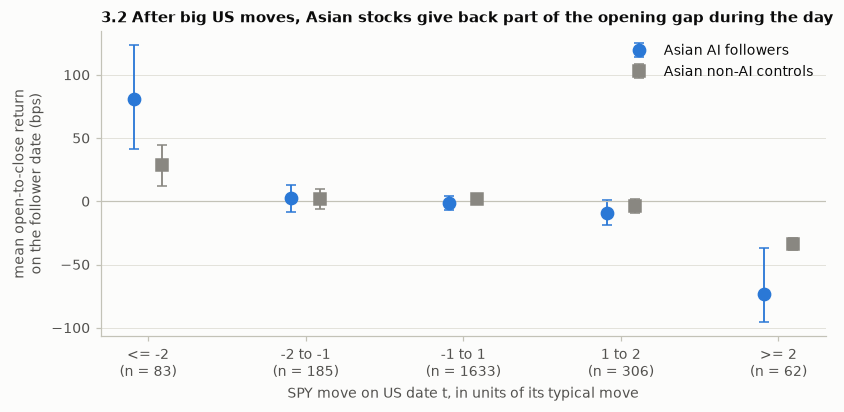

In [25]:
# Mean open-to-close return of the followers by size of the US market move (the shape of the reversal).
buckets = pd.cut(spy_z, [-np.inf, -2, -1, 1, 2, np.inf], labels=["<= -2", "-2 to -1", "-1 to 1", "1 to 2", ">= 2"])
fig, ax = plt.subplots(figsize=(8.5, 3.6))
xb = np.arange(len(buckets.cat.categories))
for i, (label, tickers, color, marker) in enumerate([("Asian AI followers", ASIA_AI, REAL, "o"),
                                                     ("Asian non-AI controls", ASIA_CTRL, MUTED, "s")]):
    daily_oc = FR["oc"][tickers].mean(axis=1) * 1e4
    means, los, his = [], [], []
    for b in buckets.cat.categories:
        d = daily_oc[buckets == b]
        lo, hi = block_bootstrap_mean(d, n_boot=300)
        means.append(d.mean()); los.append(lo); his.append(hi)
    means = np.array(means)
    pos = xb + (i - 0.5) * 0.18
    ax.errorbar(pos, means, yerr=[means - np.array(los), np.array(his) - means], fmt=marker, color=color,
                markersize=8, lw=1.2, capsize=3, label=label)
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xticks(xb, [f"{c}\n(n = {(buckets == c).sum()})" for c in buckets.cat.categories])
ax.set_xlabel("SPY move on US date t, in units of its typical move")
ax.set_ylabel("mean open-to-close return\non the follower date (bps)")
ax.set_title("3.2 After big US moves, Asian stocks give back part of the opening gap during the day")
ax.grid(axis="y")
ax.legend(frameon=False, loc="upper right")
save(fig, "s3_2_reversal_by_spy_move")
plt.show()

## What Stage 3 shows
Numbers printed from this run.

In [26]:
print("3.1 Same rules scored on three parts of the follower day (excess = direction right, real minus chance):")
for g in TRADE_GROUPS:
    v = survival[g]
    print(f"  ({g}) {GROUP_LABEL[g]:30s} cc {v['excess_cc']:+.3f}   gap {v['excess_gap']:+.3f}   oc {v['excess_oc']:+.3f}"
          f"   (oc CI {fmt_ci(TRADE['oc'].loc[g, 'excess 95% CI'])})")
print("3.2 Reversal rules (opposite-direction, open-to-close followers):")
for g, r in rev_table.iterrows():
    print(f"  {g:38s} direction right {r['direction right (real)']:.1%} {fmt_ci(r['direction right (real) 95% CI'])} "
          f"vs 50% without a reversal; chance rules {r['direction right (null)']:.1%}")
print("3.2 Size of the reversal on big-SPY-move days (bps per day, equal-weight, per-market round-trip costs):")
for (f, m), r in size_table.iterrows():
    print(f"  {f:7s} {m:4s} ({r['stocks']:2d} stocks) gross {r['mean reversal, gross (bps)']:6.1f}  cost "
          f"{r['mean round-trip cost (bps)']:5.1f}  net {r['net (bps)']:+6.1f} {r['net 95% CI']:>16s}  "
          f"net without top 1% |gap| {r['net without top 1% |gap| (bps)']:+6.1f}")
pos_years = (by_year["Asian AI followers"] > 0).sum()
print(f"  AI followers: positive in {pos_years} of {len(by_year)} years")

3.1 Same rules scored on three parts of the follower day (excess = direction right, real minus chance):
  (b) US AI -> Asian AI              cc +0.229   gap +0.219   oc +0.084   (oc CI [+0.037, +0.132])
  (c) US non-AI -> Asian non-AI      cc +0.222   gap +0.224   oc +0.144   (oc CI [+0.051, +0.238])
  (d) US AI -> Asian non-AI          cc +0.152   gap +0.153   oc +0.020   (oc CI [-0.063, +0.103])
  (f) US non-AI -> Asian AI          cc +0.208   gap +0.217   oc +0.033   (oc CI [-0.037, +0.103])
3.2 Reversal rules (opposite-direction, open-to-close followers):
  (r1) SPY -> Asian AI (oc)              direction right 80.0% [+0.681, +0.919] vs 50% without a reversal; chance rules 79.2%
  (r2) SPY -> Asian non-AI (oc)          direction right 68.2% [+0.488, +0.875] vs 50% without a reversal; chance rules 66.7%
  (r3) US AI -> Asian AI (oc)            direction right 51.6% [+0.442, +0.590] vs 50% without a reversal; chance rules 46.7%
  (r4) US non-AI -> Asian non-AI (oc)    direction right

**Reading the results.**
* **Information arrives in the gap.** Scoring the Stage 2 rules on the overnight gap (previous close -> open)
  gives the same excess as close-to-close: the transmission is priced at the Asian open, before anyone in Asia
  can trade on it. After the open, a small part of the direction signal remains for US AI -> Asian AI and for the
  non-AI control, and none for the two cross groups, so the tradeable part is small and again not AI-specific.
* **After big market moves, part of the opening gap reverses during the Asian day** (exploratory: suggested by
  Stage 1). For AI followers, opposite-direction rules from SPY beat their mirror rules far more often than half
  the time (for the non-AI controls only a few rules are mined and the interval includes 50%); the correlation
  pattern holds stock by stock (including Taiwan, where we cannot use the index), it is not caused by stale opens
  or zero-volume days, and it survives dropping the 1% largest gaps. It is stronger for AI followers than for the
  non-AI controls.
* **Whether it survives costs depends on the market's tax.** Over all AI followers the reversal is about the size
  of the average round-trip cost, so roughly break-even. Per market it differs: in Japan (no transaction tax) the
  AI followers keep a positive net return after costs, even without the most extreme days; in Korea the
  transaction tax takes almost all of it; in Taiwan the reversal is smaller and the day-trade tax makes it
  negative. The non-AI controls do not cover costs in any market. This fits a "limits to arbitrage" reading
  (a guess, not tested here): an overreaction at the open can persist where the tax makes correcting it unprofitable.
  Figure 3.2 shows the reversal is concentrated after the largest US moves (at least 2 typical moves) and close to
  zero after moves of 1-2. We saw this only by looking at the figure, so a rule like "trade only after 2+ moves"
  would need its own test on new data before anyone relied on it.
* **Overall:** the cross-time-zone structure is real and large, but almost all of it is in prices by the time
  Asian markets open, which is what an efficient market predicts for information that arrives while it is closed.

# Stage 4. Prediction: does a trained model beat one or two mined rules?

**Target.** For each Asian AI follower and follower date: is the stock's **residual open-to-close** return
positive (main; the part you can trade after seeing the US close)? Secondary target: residual close-to-close.
"Residual" = the stock's return minus the average return of the other stocks of the same market in our data
that day. We do not use the home index here because the ^TWII opening value is stale (Stage 1), so an index-based
open-to-close residual would be wrong for Taiwan.

**Feature sets** (all known before the trade at the Asian open; history features use local days before the
follower date only):
* **A:** the follower's own history (residual z-score of the last local day, 5- and 20-day residual return, 20-day
  volatility, home-index 1- and 5-day return) and, for the open-to-close target only, the stock's own opening gap
  (known at the open; for close-to-close it is part of the target, so it is left out).
* **A+US:** A + the continuous residual returns of the 9 US AI leaders on US date *t* and the SPY return on *t*
  (the "linear transmission" baseline).
* **B:** A+US + rule features from the Stage 2 rules (group b) mined on the three years before the test year:
  lag score up / down / net (sum over fired rules of confidence minus base rate) and the number of fired rules.

**Walk-forward.** Rule features exist from 2019 (the first test year of the rules). Models train on all feature
years before the test year (2019 to Y-1) and are tested on Y = 2021-2026. Scalers and imputers are fitted inside
each training set only.

**Benchmarks every model must beat** (same test years, same stocks):
* **drift:** trade in the direction of the fired Stage 2 rules (score = net lag score), open to close;
* **fade:** after a SPY move of at least 2 typical moves, trade against the stock's own opening gap. The threshold
  of 2 was suggested by Figure 3.2 (after looking at the data), so this benchmark is generous to the fade idea.

In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

FIRST_MODEL_TEST_YEAR = 2021      # models train on 2019..Y-1 (rule features start in 2019)
MODEL_TEST_YEARS = [Y for Y in TEST_YEARS if Y >= FIRST_MODEL_TEST_YEAR]
FADE_Z = 2.0                      # fade benchmark: |SPY move| >= 2 typical moves
TOP_FRACTION = 0.2                # long/short: long the top 20% of followers, short the bottom 20%
N_BOOT_AUC = 300


def peer_residual(ret_rows):
    # Return minus the mean of the OTHER Asian stocks of the same market on the same row.
    out = {}
    for t in ASIA_AI:
        peers = [p for p in ASIA_ALL if MARKET_OF[p] == MARKET_OF[t] and p != t]
        out[t] = ret_rows[t] - ret_rows[peers].mean(axis=1)
    return pd.DataFrame(out)


def history_features():
    # Follower history known before the follower date (shift(1) on the local calendar), moved onto rows t.
    feats = {k: [] for k in ["res_z_prev", "res_5d", "res_20d", "vol_20d", "index_1d", "index_5d"]}
    for market in ["JP", "KR", "TW"]:
        ts = [t for t in ASIA_AI if MARKET_OF[t] == market]
        index = {"JP": "^N225", "KR": "^KS11", "TW": "^TWII"}[market]
        cc = local_returns(CLOSE, OPEN, ts + [index], market_calendar(market))[0]
        res = residuals(cc[ts], cc[index], BETA_WINDOW)
        pairs = calendar[calendar["market"] == market]
        local = {"res_z_prev": zscores(res, VOL_WINDOW).shift(1), "res_5d": res.rolling(5).sum().shift(1),
                 "res_20d": res.rolling(20).sum().shift(1), "vol_20d": cc[ts].rolling(20).std().shift(1),
                 "index_1d": pd.DataFrame({t: cc[index].shift(1) for t in ts}),
                 "index_5d": pd.DataFrame({t: cc[index].rolling(5).sum().shift(1) for t in ts})}
        for k, v in local.items():
            feats[k].append(follower_frame(v, pairs))
    return {k: pd.concat(v, axis=1, sort=True).reindex(ROWS)[ASIA_AI] for k, v in feats.items()}


def rule_features():
    # Lag scores per (row, follower) from the rules mined on the 3 years before each row's year (no look-ahead).
    basket = GROUPS["b"][1]
    out = {k: pd.DataFrame(0.0, index=ROWS, columns=ASIA_AI) for k in ["lag_up", "lag_down", "lag_n"]}
    for Y in TEST_YEARS:
        rules = RESULTS["b"]["real"][Y]
        days = test_rows(Y)
        if len(rules) == 0:
            continue
        assert train_rows(Y).max() < days.min(), "rule features must come from earlier years"
        fired, _, _ = rule_day_matrices(rules, basket.loc[days])
        weight = (rules["confidence"] - rules["base_rate"]).to_numpy()
        for j, cons in enumerate(rules["consequent"]):
            t = ticker_of(cons)
            key = "lag_up" if direction_of(cons) == "UP" else "lag_down"
            out[key].loc[days, t] += fired[:, j] * weight[j]
            out["lag_n"].loc[days, t] += fired[:, j]
    out["lag_net"] = out["lag_up"] - out["lag_down"]
    return out


FR_AI = {k: v[ASIA_AI] for k, v in FR.items()}
TARGETS = {"oc": peer_residual(FR["oc"]), "cc": peer_residual(FR["cc"])}
HIST = history_features()
RULEF = rule_features()
us_res = local_returns(CLOSE, OPEN, US_AI + ["SPY"], US_DAYS)[0]
US_FEATS = residuals(us_res[US_AI], us_res["SPY"], BETA_WINDOW).add_prefix("us_").reindex(ROWS)
US_FEATS["spy_ret"] = us_res["SPY"].reindex(ROWS)


def long_panel():
    # One row per (US date t, follower): features, targets, raw open-to-close return, market, cost.
    frames = {**HIST, **RULEF, "gap_today": FR_AI["gap"], "raw_oc": FR_AI["oc"], "raw_cc": FR_AI["cc"],
              "cost_bps": COSTS[ASIA_AI],
              "res_oc": TARGETS["oc"], "res_cc": TARGETS["cc"]}
    panel = pd.concat({k: v[ASIA_AI].stack() for k, v in frames.items()}, axis=1)      # keeps missing values
    panel.index.names = ["date", "ticker"]
    panel = panel.reset_index()
    panel = panel.merge(US_FEATS, left_on="date", right_index=True, how="left")
    panel["market"] = panel["ticker"].map(MARKET_OF)
    panel["year"] = panel["date"].dt.year
    panel["spy_z"] = panel["date"].map(spy_z)
    return panel[panel["year"] >= FIRST_TEST_YEAR].reset_index(drop=True)


PANEL = long_panel()
F_A = ["res_z_prev", "res_5d", "res_20d", "vol_20d", "index_1d", "index_5d"]
F_US = list(US_FEATS.columns)
F_RULES = ["lag_up", "lag_down", "lag_net", "lag_n"]
FEATURE_SETS = {"oc": {"A": F_A + ["gap_today"], "A+US": F_A + ["gap_today"] + F_US,
                       "B": F_A + ["gap_today"] + F_US + F_RULES},
                "cc": {"A": F_A, "A+US": F_A + F_US, "B": F_A + F_US + F_RULES}}
# Target robustness: the same models on RAW returns (return > 0). The peer-average residual removes any move common
# to the AI stocks of a market (Taiwan and Korea peers are mostly AI followers), which can hide US transmission.
FEATURE_SETS["oc_raw"], FEATURE_SETS["cc_raw"] = FEATURE_SETS["oc"], FEATURE_SETS["cc"]
TARGET_COLUMN = {"oc": "res_oc", "cc": "res_cc", "oc_raw": "raw_oc", "cc_raw": "raw_cc"}
print(f"panel: {len(PANEL)} rows ({PANEL['ticker'].nunique()} followers x {PANEL['date'].nunique()} dates), "
      f"{PANEL['year'].min()}-{PANEL['year'].max()}; share of positive residual oc: "
      f"{(PANEL['res_oc'] > 0).mean():.3f}")

panel: 26848 rows (16 followers x 1678 dates), 2019-2026; share of positive residual oc: 0.484


In [28]:
def make_model(name):
    if name == "logistic":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=300,
                                          l2_regularization=1.0, random_state=SEED)


def walk_forward_models(panel):
    # Train on 2019..Y-1, predict year Y, for every target x model x feature set.
    preds, coefs = [], []
    for target, sets in FEATURE_SETS.items():
        ycol = TARGET_COLUMN[target]
        data = panel[panel[ycol].notna()]
        for model_name in ["logistic", "boosting"]:
            for fs, cols in sets.items():
                for Y in MODEL_TEST_YEARS:
                    train, test = data[data["year"] < Y], data[data["year"] == Y]
                    assert train["date"].max() < test["date"].min(), "look-ahead in model training"
                    m = make_model(model_name).fit(train[cols], train[ycol] > 0)
                    preds.append(pd.DataFrame({"date": test["date"].values, "ticker": test["ticker"].values,
                                               "y": (test[ycol] > 0).values, "prob": m.predict_proba(test[cols])[:, 1],
                                               "target": target, "model": model_name, "features": fs, "year": Y}))
                    if model_name == "logistic":
                        coefs.append(pd.Series(m[-1].coef_[0], index=cols, name=(target, fs, Y)))
    return pd.concat(preds, ignore_index=True), coefs


PREDS, COEFS = cached("stage4_preds", lambda: walk_forward_models(PANEL))

# Benchmarks as scores on the same rows: drift = net lag score; fade = against the own gap after a 2+ SPY move.
bench = PANEL[PANEL["res_oc"].notna()].copy()
bench["drift"] = bench["lag_net"]
bench["fade"] = np.where(bench["spy_z"].abs() >= FADE_Z, -np.sign(bench["gap_today"]), 0.0)
for b in ["drift", "fade"]:
    for target, ycol in TARGET_COLUMN.items():
        d = PANEL[PANEL[ycol].notna() & PANEL["year"].isin(MODEL_TEST_YEARS)].copy()   # same rows as models
        score = d["lag_net"] if b == "drift" else np.where(d["spy_z"].abs() >= FADE_Z, -np.sign(d["gap_today"]), 0.0)
        PREDS = pd.concat([PREDS, pd.DataFrame({"date": d["date"].values, "ticker": d["ticker"].values,
                                                "y": (d[ycol] > 0).values, "prob": np.nan_to_num(score),
                                                "target": target, "model": "rule benchmark", "features": b,
                                                "year": d["year"].values})], ignore_index=True)
print(f"models done at {time.time() - T0:.0f} s")

models done at 140 s


### 4.1 Out-of-sample AUC (0.5 = coin flip)

In [29]:
auc_by_year = (PREDS.groupby(["target", "model", "features", "year"])
               .apply(lambda d: roc_auc_score(d["y"], d["prob"]), include_groups=False).unstack("year"))
auc_by_year["pooled"] = PREDS.groupby(["target", "model", "features"]).apply(
    lambda d: roc_auc_score(d["y"], d["prob"]), include_groups=False)
auc_by_year.to_csv(OUT_DIR / "s4_auc_by_year.csv")
KEY["auc"] = {" | ".join(k): v for k, v in auc_by_year.round(4).to_dict(orient="index").items()}
auc_by_year.round(3)

year                             2021   2022   2023   2024   2025   2026  \
target model          features                                             
cc     boosting       A         0.485  0.488  0.512  0.498  0.525  0.526   
                      A+US      0.532  0.540  0.550  0.565  0.542  0.547   
                      B         0.533  0.545  0.541  0.565  0.543  0.545   
       logistic       A         0.499  0.497  0.526  0.504  0.522  0.540   
                      A+US      0.537  0.534  0.535  0.556  0.543  0.547   
                      B         0.548  0.532  0.546  0.562  0.544  0.552   
       rule benchmark drift     0.546  0.524  0.544  0.526  0.518  0.543   
                      fade      0.493  0.494  0.496  0.484  0.484  0.490   
cc_raw boosting       A         0.480  0.504  0.517  0.503  0.516  0.525   
                      A+US      0.583  0.688  0.632  0.681  0.633  0.653   
                      B         0.591  0.683  0.627  0.680  0.635  0.646   
       logistic       A         0.497  0.510  0.525  0.499  0.502  0.495   
                      A+US      0.600  0.700  0.661  0.665  0.643  0.661   
                      B         0.603  0.696  0.663  0.667  0.644  0.662   
       rule benchmark drift     0.549  0.529  0.555  0.536  0.537  0.580   
                      fade      0.478  0.459  0.488  0.463  0.463  0.450   
oc     boosting       A         0.498  0.515  0.552  0.518  0.526  0.537   
                      A+US      0.509  0.526  0.546  0.521  0.528  0.534   
                      B         0.519  0.520  0.541  0.525  0.528  0.537   
       logistic       A         0.516  0.520  0.542  0.532  0.509  0.532   
                      A+US      0.521  0.520  0.539  0.530  0.504  0.523   
                      B         0.527  0.526  0.539  0.531  0.505  0.521   
       rule benchmark drift     0.511  0.506  0.507  0.498  0.499  0.497   
                      fade      0.500  0.506  0.501  0.497  0.497  0.503   
oc_raw boosting       A         0.520  0.531  0.557  0.520  0.504  0.544   
                      A+US      0.518  0.530  0.553  0.513  0.496  0.546   
                      B         0.518  0.541  0.544  0.512  0.502  0.548   
       logistic       A         0.530  0.508  0.545  0.517  0.509  0.525   
                      A+US      0.525  0.529  0.553  0.496  0.512  0.556   
                      B         0.532  0.531  0.554  0.503  0.519  0.553   
       rule benchmark drift     0.509  0.497  0.522  0.486  0.498  0.502   
                      fade      0.511  0.519  0.504  0.497  0.514  0.518   

year                            pooled  
target model          features          
cc     boosting       A          0.503  
                      A+US       0.544  
                      B          0.542  
       logistic       A          0.513  
                      A+US       0.541  
                      B          0.546  
       rule benchmark drift      0.533  
                      fade       0.490  
cc_raw boosting       A          0.504  
                      A+US       0.646  
                      B          0.645  
       logistic       A          0.499  
                      A+US       0.655  
                      B          0.655  
       rule benchmark drift      0.549  
                      fade       0.467  
oc     boosting       A          0.521  
                      A+US       0.523  
                      B          0.526  
       logistic       A          0.527  
                      A+US       0.524  
                      B          0.526  
       rule benchmark drift      0.503  
                      fade       0.501  
oc_raw boosting       A          0.528  
                      A+US       0.526  
                      B          0.527  
       logistic       A          0.521  
                      A+US       0.527  
                      B          0.530  
       rule benchmark drift      0.503  
                      fade       0.510

In [30]:
def preds_of(target, model, fs):
    return PREDS[(PREDS.target == target) & (PREDS.model == model) & (PREDS.features == fs)].sort_values(["date", "ticker"])


def block_bootstrap_auc_diff(pa, pb, n_boot=N_BOOT_AUC, block=BOOT_BLOCK, seed=SEED):
    # Difference in pooled AUC (b - a), resampling 21-day blocks of test dates; pa and pb share rows and order.
    rng = np.random.default_rng(seed)
    d = pa["date"].to_numpy()
    days, starts = np.unique(d, return_index=True)
    ends = np.append(starts[1:], len(d))
    blocks = [np.arange(starts[i], ends[min(i + block, len(days)) - 1]) for i in range(0, len(days), block)]
    y, qa, qb = pa["y"].to_numpy(), pa["prob"].to_numpy(), pb["prob"].to_numpy()
    diffs = []
    for _ in range(n_boot):
        idx = np.concatenate([blocks[i] for i in rng.integers(0, len(blocks), len(blocks))])
        diffs.append(roc_auc_score(y[idx], qb[idx]) - roc_auc_score(y[idx], qa[idx]))
    est = roc_auc_score(y, qb) - roc_auc_score(y, qa)
    return est, se_interval(est, np.array(diffs))


comparisons = []
for target in TARGET_COLUMN:
    for model in ["logistic", "boosting"]:
        for a, b in [("A", "A+US"), ("A+US", "B")]:
            pa, pb = preds_of(target, model, a), preds_of(target, model, b)
            assert (pa["date"].values == pb["date"].values).all() and (pa["ticker"].values == pb["ticker"].values).all()
            est, ci = block_bootstrap_auc_diff(pa, pb)
            comparisons.append({"target": target, "model": model, "comparison": f"{b} - {a}", "AUC difference": est,
                                "95% CI": fmt_ci(ci), "years better": int((auc_by_year.loc[(target, model, b), MODEL_TEST_YEARS]
                                                                           > auc_by_year.loc[(target, model, a), MODEL_TEST_YEARS]).sum()),
                                "of years": len(MODEL_TEST_YEARS)})
        pd_, pb = preds_of(target, "rule benchmark", "drift"), preds_of(target, model, "B")
        est, ci = block_bootstrap_auc_diff(pd_, pb)
        comparisons.append({"target": target, "model": model, "comparison": "B - drift benchmark", "AUC difference": est,
                            "95% CI": fmt_ci(ci), "years better": int((auc_by_year.loc[(target, model, "B"), MODEL_TEST_YEARS]
                                                                       > auc_by_year.loc[(target, "rule benchmark", "drift"), MODEL_TEST_YEARS]).sum()),
                            "of years": len(MODEL_TEST_YEARS)})
comparisons = pd.DataFrame(comparisons)
comparisons.to_csv(OUT_DIR / "s4_model_comparisons.csv", index=False)
KEY["model_comparisons"] = comparisons.round(4).to_dict(orient="records")
comparisons[comparisons["target"].isin(["oc", "cc"])].round(4)

,target,model,comparison,AUC difference,95% CI,years better,of years
0,oc,logistic,A+US - A,-0.0029,"[-0.007, +0.001]",2,6
1,oc,logistic,B - A+US,0.0018,"[-0.001, +0.005]",4,6
2,oc,logistic,B - drift benchmark,0.0227,"[+0.014, +0.032]",6,6
3,oc,boosting,A+US - A,0.0020,"[-0.003, +0.007]",4,6
4,oc,boosting,B - A+US,0.0029,"[-0.002, +0.008]",4,6
5,oc,boosting,B - drift benchmark,0.0235,"[+0.012, +0.034]",6,6
6,cc,logistic,A+US - A,0.0276,"[+0.019, +0.036]",6,6
7,cc,logistic,B - A+US,0.0053,"[+0.002, +0.009]",5,6
8,cc,logistic,B - drift benchmark,0.0134,"[+0.007, +0.020]",6,6
9,cc,boosting,A+US - A,0.0410,"[+0.031, +0.051]",6,6


### 4.1b Target robustness: residual vs raw target, side by side
Same models, same features, same rows; only the target changes. If the US or rule features help with the raw
target but not with the residual one, the information they carry is a move common to the AI stocks of a market
(which the peer residual removes by construction), not stock-specific.

In [31]:
def side_by_side(day_part):
    rows = []
    for (model, comp), g in comparisons[comparisons["target"].isin([day_part, f"{day_part}_raw"])].groupby(
            ["model", "comparison"], sort=False):
        r = {f"{'raw' if t.endswith('raw') else 'residual'}: {k}": v
             for t, gg in g.groupby("target") for k, v in
             {"AUC diff": gg["AUC difference"].iloc[0], "95% CI": gg["95% CI"].iloc[0]}.items()}
        rows.append({"model": model, "comparison": comp, **r})
    return pd.DataFrame(rows).set_index(["model", "comparison"])


pooled_auc = auc_by_year["pooled"].unstack("target")[["oc", "oc_raw", "cc", "cc_raw"]]
pooled_auc.columns = ["oc residual", "oc raw", "cc residual", "cc raw"]
robust_target = {"open-to-close": side_by_side("oc"), "close-to-close": side_by_side("cc")}
for k, v in robust_target.items():
    v.to_csv(OUT_DIR / f"s4_target_robustness_{k}.csv")
KEY["target_robustness"] = {"pooled_auc": {" | ".join(i): v for i, v in pooled_auc.round(4).to_dict(orient="index").items()},
                            **{k: {" | ".join(i): r for i, r in v.round(4).to_dict(orient="index").items()}
                               for k, v in robust_target.items()}}
pooled_auc.round(3)

oc residual  oc raw  cc residual  cc raw
model          features                                          
boosting       A               0.521   0.528        0.503   0.504
               A+US            0.523   0.526        0.544   0.646
               B               0.526   0.527        0.542   0.645
logistic       A               0.527   0.521        0.513   0.499
               A+US            0.524   0.527        0.541   0.655
               B               0.526   0.530        0.546   0.655
rule benchmark drift           0.503   0.503        0.533   0.549
               fade            0.501   0.510        0.490   0.467

In [32]:
robust_target["open-to-close"].round(4)

residual: AUC diff  residual: 95% CI  \
model    comparison                                                  
logistic A+US - A                        -0.0029  [-0.007, +0.001]   
         B - A+US                         0.0018  [-0.001, +0.005]   
         B - drift benchmark              0.0227  [+0.014, +0.032]   
boosting A+US - A                         0.0020  [-0.003, +0.007]   
         B - A+US                         0.0029  [-0.002, +0.008]   
         B - drift benchmark              0.0235  [+0.012, +0.034]   

                              raw: AUC diff       raw: 95% CI  
model    comparison                                            
logistic A+US - A                    0.0057  [-0.007, +0.018]  
         B - A+US                    0.0031  [-0.000, +0.006]  
         B - drift benchmark         0.0272  [+0.015, +0.039]  
boosting A+US - A                   -0.0025  [-0.015, +0.010]  
         B - A+US                    0.0011  [-0.005, +0.007]  
         B - drift benchmark         0.0240  [+0.011, +0.037]

In [33]:
robust_target["close-to-close"].round(4)

residual: AUC diff  residual: 95% CI  \
model    comparison                                                  
logistic A+US - A                         0.0276  [+0.019, +0.036]   
         B - A+US                         0.0053  [+0.002, +0.009]   
         B - drift benchmark              0.0134  [+0.007, +0.020]   
boosting A+US - A                         0.0410  [+0.031, +0.051]   
         B - A+US                        -0.0016  [-0.007, +0.004]   
         B - drift benchmark              0.0089  [-0.001, +0.019]   

                              raw: AUC diff       raw: 95% CI  
model    comparison                                            
logistic A+US - A                    0.1561  [+0.135, +0.177]  
         B - A+US                    0.0001  [-0.002, +0.002]  
         B - drift benchmark         0.1065  [+0.088, +0.125]  
boosting A+US - A                    0.1421  [+0.122, +0.162]  
         B - A+US                   -0.0012  [-0.005, +0.002]  
         B - drift benchmark         0.0962  [+0.079, +0.114]

### 4.2 Trading test with per-market costs

All strategies trade open -> close on the follower date (raw returns), so every position is one intraday round
trip charged at its market's cost (Japan 10 bps, Taiwan 20 bps, Korea 20-35 bps by year).
* **models:** each day, long the 20% of followers with the highest predicted probability, short the 20% with the
  lowest (equal weights, gross exposure 1);
* **drift:** long the followers with a positive net lag score, short those with a negative one (only on days
  with fired rules);
* **fade:** after a SPY move of 2+ typical moves, take a position against each follower's opening gap.

In [34]:
RAW = PANEL.set_index(["date", "ticker"])[["raw_oc", "cost_bps", "market"]]


def daily_pnl(weights):
    # weights: DataFrame (date, ticker, w). Returns daily gross and cost in bps (gross exposure 1 on trading days).
    w = weights.join(RAW, on=["date", "ticker"])
    w = w[w["raw_oc"].notna() & (w["w"] != 0)]
    w["w"] = w["w"] / w.groupby("date")["w"].transform(lambda x: x.abs().sum())
    g = w.assign(gross=w["w"] * w["raw_oc"] * 1e4, cost=w["w"].abs() * w["cost_bps"]).groupby("date")[["gross", "cost"]].sum()
    return g


def model_weights(p, top=TOP_FRACTION):
    rows = []
    for d, g in p.groupby("date"):
        k = max(1, int(round(top * len(g))))
        g = g.sort_values("prob")
        rows += [(d, t, -1.0) for t in g["ticker"].iloc[:k]] + [(d, t, 1.0) for t in g["ticker"].iloc[-k:]]
    return pd.DataFrame(rows, columns=["date", "ticker", "w"])


def summarise_pnl(g, n_test_days, label):
    net = g["gross"] - g["cost"]
    years = n_test_days / 252
    daily_all = net.reindex(sorted(PANEL.loc[PANEL["year"].isin(MODEL_TEST_YEARS), "date"].unique()), fill_value=0)
    return {"strategy": label, "trading days": len(g), "gross per trading day (bps)": g["gross"].mean(),
            "cost per trading day (bps)": g["cost"].mean(), "net per trading day (bps)": net.mean(),
            "net % per year": net.sum() / years / 100,
            "net Sharpe (annualised)": np.sqrt(252) * daily_all.mean() / daily_all.std() if daily_all.std() > 0 else np.nan,
            "gross / cost": g["gross"].mean() / g["cost"].mean() if g["cost"].mean() > 0 else np.nan}


test_dates = PANEL.loc[PANEL["year"].isin(MODEL_TEST_YEARS), "date"].unique()
trading, curves = [], {}
for model in ["logistic", "boosting"]:
    for fs in ["A", "A+US", "B"]:
        g = daily_pnl(model_weights(preds_of("oc", model, fs)))
        trading.append(summarise_pnl(g, len(test_dates), f"{model}, {fs}"))
        curves[f"{model}, {fs}"] = g
b = bench[bench["year"].isin(MODEL_TEST_YEARS)]
drift_w = b.assign(w=np.sign(b["drift"]))[["date", "ticker", "w"]]
fade_w = b.assign(w=b["fade"])[["date", "ticker", "w"]]
for label, w in [("drift benchmark (Stage 2 rules)", drift_w), ("fade benchmark (SPY 2+ moves)", fade_w)]:
    g = daily_pnl(w)
    trading.append(summarise_pnl(g, len(test_dates), label))
    curves[label] = g
trading = pd.DataFrame(trading).set_index("strategy")
trading.to_csv(OUT_DIR / "s4_trading_test.csv")
KEY["trading"] = trading.round(3).to_dict(orient="index")
trading.round(2)

,trading days,gross per trading day (bps),cost per trading day (bps),net per trading day (bps),net % per year,net Sharpe (annualised),gross / cost
strategy,,,,,,,
"logistic, A",1251,14.82,16.85,-2.03,-5.12,-0.33,0.88
"logistic, A+US",1251,14.51,17.00,-2.49,-6.28,-0.40,0.85
"logistic, B",1251,16.80,16.91,-0.11,-0.27,-0.02,0.99
"boosting, A",1251,12.04,17.22,-5.17,-13.04,-0.92,0.70
"boosting, A+US",1251,12.45,17.17,-4.72,-11.90,-0.81,0.73
"boosting, B",1251,13.73,17.14,-3.41,-8.59,-0.58,0.80
drift benchmark (Stage 2 rules),1055,3.42,15.43,-12.01,-25.52,-1.33,0.22
fade benchmark (SPY 2+ moves),74,54.67,17.70,36.97,5.51,0.79,3.09


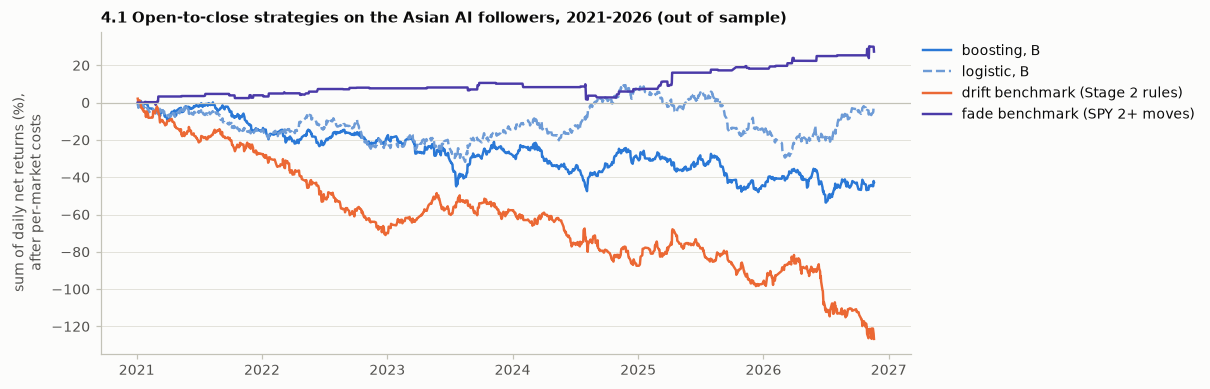

In [35]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
show_curves = {"boosting, B": (REAL, "-"), "logistic, B": ("#6d9bd6", "--"),
               "drift benchmark (Stage 2 rules)": (ASIA_COLOR, "-"), "fade benchmark (SPY 2+ moves)": ("#4a3aa8", "-")}
all_dates = pd.DatetimeIndex(sorted(test_dates))
for label, (color, ls) in show_curves.items():
    g = curves[label]
    net = (g["gross"] - g["cost"]).reindex(all_dates, fill_value=0) / 1e4
    ax.plot(all_dates, net.cumsum() * 100, color=color, ls=ls, lw=1.6, label=label)
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_ylabel("sum of daily net returns (%),\nafter per-market costs")
ax.set_title("4.1 Open-to-close strategies on the Asian AI followers, 2021-2026 (out of sample)")
ax.grid(axis="y")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
save(fig, "s4_1_cumulative_net")
plt.show()

### 4.3 Which features does the logistic model use, and are the signs stable across years?
Standardised coefficients of the logistic model with feature set B (open-to-close target), one per test year.

In [36]:
coef = pd.DataFrame([c for c in COEFS if c.name[0] == "oc" and c.name[1] == "B"])
coef.index = [c[2] for c in coef.index]
coef_summary = pd.DataFrame({"mean coefficient": coef.mean(), "years positive": (coef > 0).sum(),
                             "of years": len(coef)}).sort_values("mean coefficient", key=np.abs, ascending=False)
coef_summary.to_csv(OUT_DIR / "s4_logistic_coefficients.csv")
KEY["logistic_coefficients_oc_B"] = coef_summary.round(4).to_dict(orient="index")
coef_summary.round(3)

,mean coefficient,years positive,of years
gap_today,-0.106,0,6
res_5d,-0.076,0,6
res_z_prev,-0.072,0,6
res_20d,0.056,6,6
lag_n,0.050,6,6
spy_ret,0.049,6,6
index_1d,-0.042,0,6
us_MU,0.037,6,6
lag_down,-0.034,0,6
us_AMD,0.031,6,6


## What Stage 4 shows
Numbers printed from this run.

In [37]:
au = auc_by_year["pooled"]
print("Pooled out-of-sample AUC, 2021-2026 (main target: residual open-to-close > 0):")
for model in ["logistic", "boosting"]:
    print(f"  {model:9s} A {au[('oc', model, 'A')]:.3f}   A+US {au[('oc', model, 'A+US')]:.3f}   B {au[('oc', model, 'B')]:.3f}"
          f"      (close-to-close: A {au[('cc', model, 'A')]:.3f}, A+US {au[('cc', model, 'A+US')]:.3f}, B {au[('cc', model, 'B')]:.3f})")
print(f"  benchmarks: drift {au[('oc', 'rule benchmark', 'drift')]:.3f}, fade {au[('oc', 'rule benchmark', 'fade')]:.3f}")
for _, r in comparisons.iterrows():
    print(f"  {r['target']} {r['model']:9s} {r['comparison']:20s} {r['AUC difference']:+.4f} {r['95% CI']}  "
          f"better in {r['years better']} of {r['of years']} years")
print("Trading (open -> close, per-market costs):")
for k, r in trading.iterrows():
    print(f"  {k:32s} {r['trading days']:5.0f} days  gross {r['gross per trading day (bps)']:6.1f}  cost "
          f"{r['cost per trading day (bps)']:5.1f}  net {r['net per trading day (bps)']:+6.1f} bps/day  "
          f"{r['net % per year']:+6.1f}% per year")
stable = coef_summary[(coef_summary["years positive"] == 0) | (coef_summary["years positive"] == coef_summary["of years"])]
print(f"Logistic (B, oc): features with the same sign in every year: {', '.join(stable.index[:8])}")

Pooled out-of-sample AUC, 2021-2026 (main target: residual open-to-close > 0):
  logistic  A 0.527   A+US 0.524   B 0.526      (close-to-close: A 0.513, A+US 0.541, B 0.546)
  boosting  A 0.521   A+US 0.523   B 0.526      (close-to-close: A 0.503, A+US 0.544, B 0.542)
  benchmarks: drift 0.503, fade 0.501
  oc logistic  A+US - A             -0.0029 [-0.007, +0.001]  better in 2 of 6 years
  oc logistic  B - A+US             +0.0018 [-0.001, +0.005]  better in 4 of 6 years
  oc logistic  B - drift benchmark  +0.0227 [+0.014, +0.032]  better in 6 of 6 years
  oc boosting  A+US - A             +0.0020 [-0.003, +0.007]  better in 4 of 6 years
  oc boosting  B - A+US             +0.0029 [-0.002, +0.008]  better in 4 of 6 years
  oc boosting  B - drift benchmark  +0.0235 [+0.012, +0.034]  better in 6 of 6 years
  cc logistic  A+US - A             +0.0276 [+0.019, +0.036]  better in 6 of 6 years
  cc logistic  B - A+US             +0.0053 [+0.002, +0.009]  better in 5 of 6 years
  cc logistic

**Reading the results.**
* **Tradeable target (open-to-close).** The models are slightly better than a coin flip, and almost all of that
  comes from feature set A: the stock's own opening gap (negative coefficient in every year: the reversal of
  Stage 3) and its recent residual returns (short-term reversal). Adding the US leaders' returns (A+US) or the
  rule features (B) does not improve the AUC beyond noise. What is predictable after the open is the follower's
  own overreaction, not the US news.
* **Close-to-close target.** Here the US features clearly help (A+US over A): close-to-close includes the opening
  gap, which is where the US information goes (Stages 2-3). Rule features add a little on top for the logistic
  model and nothing for boosting.
* **Target robustness (raw vs residual target, table 4.1b).** With the raw close-to-close target the US features
  help far more than with the residual one: most of what the US session tells us is a move shared by all the AI
  stocks of a market, which the peer residual removes by construction. Rule features add nothing beyond the US
  returns with the raw target; their small gain appears only with the residual close-to-close target (logistic).
  For the tradeable open-to-close target, neither the US features nor the rule features help with either target.
* **A trained model vs one or two mined rules.** Every model beats the drift benchmark (trading in the direction
  of the fired Stage 2 rules) on AUC, and the drift benchmark loses heavily after costs: by the time Asia can
  trade, the rule's information is already in the opening price. But no model beats the fade benchmark in the
  trading test: one simple rule (after a 2+ typical-move SPY day, trade against the opening gap) is the only
  strategy with a positive net return, and the long/short models lose money after costs because they trade every
  day. The fade threshold was suggested by looking at the data, so this comparison flatters it; the split-sample
  test (next) is the fair version.
* **Readable rules vs the models.** The models' small edge is the same reversal the fade rule describes, spread
  over every day instead of the few days when it is large. A readable rule captures the useful part. Fischer &
  Krauss (2018, EJOR) found that deep models on daily US stocks have edges that are small and shrink after
  costs and over time; with 16 Asian stocks and six test years we should expect no more than that, and we find
  it.

# 5. Checks on the two exploratory findings

## 5.1 Is the opening-gap reversal just bid-ask bounce?

The gap (previous close -> open) and open-to-close share the opening price. If the opening print is noisy (a trade
at the bid or the ask, a thin auction), the gap and open-to-close are negatively correlated by construction. To
rule that out we start the trade one hour later: from the **close of the first hourly bar** (about 1 hour after
the open) to the daily close. A noisy opening print cannot affect that return.

Hourly bars come from Yahoo Finance (`scripts/build_dataset_v2.py`, `data/prices_hourly_v2.csv`) and cover only
the last ~730 days (from late 2023). They are not adjusted like the daily file, so we use only ratios within one
day of the hourly data. For the same stocks and days we show the open-based reversal from the daily file and
from the hourly file, next to the reversal from the first-hour close.

In [38]:
hourly = pd.read_csv("data/prices_hourly_v2.csv", parse_dates=["datetime"])
hourly["day"] = hourly["datetime"].dt.normalize()
hourly = hourly.sort_values(["ticker", "datetime"])
by_day = hourly.groupby(["ticker", "day"]).agg(first_open=("open", "first"), first_close=("close", "first"),
                                               last_close=("close", "last"), bars=("close", "size")).reset_index()
by_day = by_day[by_day["bars"] >= 3]                      # a full session has 5 (Taiwan) to 7 (Japan) bars


def hourly_on_rows(column):
    # Hourly-based daily values (one per local day) moved onto the US dates t, for the Asian AI followers.
    wide_h = by_day.pivot(index="day", columns="ticker", values=column)
    frames = []
    for market in ["JP", "KR", "TW"]:
        ts = [t for t in ASIA_AI if MARKET_OF[t] == market and t in wide_h.columns]
        frames.append(follower_frame(wide_h[ts], calendar[calendar["market"] == market]))
    return pd.concat(frames, axis=1, sort=True).reindex(ROWS)[ASIA_AI]


H_OPEN, H_FIRST, H_LAST = hourly_on_rows("first_open"), hourly_on_rows("first_close"), hourly_on_rows("last_close")
H_OC = H_LAST / H_OPEN - 1                                 # open -> close, from hourly bars
H_LATE = H_LAST / H_FIRST - 1                              # first-hour close -> close (no opening print involved)
both = H_OC.notna() & FR_AI["oc"].notna()
print(f"hourly coverage: {H_OC.notna().any(axis=1).sum()} US dates from "
      f"{H_OC.dropna(how='all').index.min().date()}; correlation of daily vs hourly open->close on the same stock-days: "
      f"{pd.concat([FR_AI['oc'].where(both).stack(), H_OC.where(both).stack()], axis=1).dropna().corr().iloc[0, 1]:.3f}")

bounce_rows = []
for z_min in [1.0, 2.0]:
    event = (spy_z.abs() >= z_min) & H_OC.notna().any(axis=1)
    s_ = -np.sign(SPY_RET).to_numpy()[:, None]
    for market in ["JP", "KR", "TW", "all"]:
        ts = [t for t in ASIA_AI if market == "all" or MARKET_OF[t] == market]
        ok = both[ts] & H_LATE[ts].notna()
        parts = {"open -> close (daily file)": FR_AI["oc"][ts], "open -> close (hourly bars)": H_OC[ts],
                 "first-hour close -> close (hourly bars)": H_LATE[ts]}
        row = {"SPY move at least": z_min, "market": market}
        for name, ret in parts.items():
            daily = (s_ * ret * 1e4).where(ok).where(event, axis=0).mean(axis=1).dropna()
            lo, hi = block_bootstrap_mean(daily)
            row[f"{name} (bps)"] = daily.mean()
            row[f"{name} 95% CI"] = f"[{lo:+.1f}, {hi:+.1f}]"
            row["event days"] = len(daily)
        row["share kept after the first hour"] = (row["first-hour close -> close (hourly bars) (bps)"]
                                                  / row["open -> close (hourly bars) (bps)"])
        bounce_rows.append(row)
bounce = pd.DataFrame(bounce_rows).set_index(["SPY move at least", "market"])
bounce = bounce[["event days"] + [c for c in bounce.columns if c != "event days"]]
bounce.to_csv(OUT_DIR / "s5_bounce_check.csv")
KEY["bounce_check"] = {f"{z} | {m}": v for (z, m), v in bounce.round(3).to_dict(orient="index").items()}
bounce.round(2)

hourly coverage: 629 US dates from 2023-11-16; correlation of daily vs hourly open->close on the same stock-days: 0.970


event days  open -> close (daily file) (bps)  \
SPY move at least market                                                 
1.0               JP             175                             34.97   
                  KR             175                             42.37   
                  TW             175                             13.24   
                  all            175                             25.49   
2.0               JP              41                            113.15   
                  KR              41                             73.41   
                  TW              41                             78.83   
                  all             41                             88.54   

                         open -> close (daily file) 95% CI  \
SPY move at least market                                     
1.0               JP                        [+12.3, +62.6]   
                  KR                         [+8.5, +77.8]   
                  TW                        [-11.6, +38.8]   
                  all                        [+5.2, +45.7]   
2.0               JP                       [+79.3, +148.6]   
                  KR                        [+6.1, +144.1]   
                  TW                       [+57.4, +101.3]   
                  all                      [+54.6, +124.1]   

                          open -> close (hourly bars) (bps)  \
SPY move at least market                                      
1.0               JP                                  32.09   
                  KR                                  44.01   
                  TW                                  15.42   
                  all                                 25.99   
2.0               JP                                 108.13   
                  KR                                  84.02   
                  TW                                  83.49   
                  all                                 91.29   

                         open -> close (hourly bars) 95% CI  \
SPY move at least market                                      
1.0               JP                         [+12.9, +56.6]   
                  KR                         [+16.5, +76.1]   
                  TW                          [-8.0, +41.4]   
                  all                         [+7.0, +46.3]   
2.0               JP                        [+79.9, +137.8]   
                  KR                         [+5.1, +166.9]   
                  TW                        [+57.2, +111.1]   
                  all                       [+54.5, +129.9]   

                          first-hour close -> close (hourly bars) (bps)  \
SPY move at least market                                                  
1.0               JP                                              13.20   
                  KR                                               1.69   
                  TW                                              11.39   
                  all                                             10.13   
2.0               JP                                              35.37   
                  KR                                               8.01   
                  TW                                              46.64   
                  all                                             35.88   

                         first-hour close -> close (hourly bars) 95% CI  \
SPY move at least market                                                  
1.0               JP                                     [-10.0, +34.6]   
                  KR                                     [-21.4, +21.8]   
                  TW                                      [-7.5, +35.5]   
                  all                                     [-2.5, +26.2]   
2.0               JP                                      [-5.3, +78.1]   
                  KR                                     [-36.0, +54.2]   
                  TW                               

## 5.2 Split-sample test of the semiconductor channel (exploratory)

Stage 2's network suggested that the lasting links run from US chipmakers to Asian chip-equipment and memory
stocks. That network used all test years (2019-2026), so it cannot test itself. Here the channel is **defined on
test years 2019-2022 only** and **tested on 2023-2026 only**:
* **semi-chain edges:** leader in {NVDA, AMD, AVGO, MU} -> any Asian AI follower, with a given direction relation,
  that held out of sample (test lift > 1 and direction right) in at least 3 of the 4 test years 2019-2022 and
  whose hold rate beats the chance hold rate over the same years;
* **test:** on 2023-2026, the scored one-item rules of group (b) are split into semi-chain edges and all other
  US AI -> Asian AI edges; the non-AI control is group (c). Same metric and bootstrap as the main comparison
  (direction right, real minus chance, 21-day blocks within test years).
* **Passes if** excess(semi) > excess(other) and > excess(control), with the intervals of both differences
  above 0.

Caveat: the test years' data is unseen, but the idea came from looking at a figure that included them.

**Correction after the first run (shown below, not hidden).** The first version compared each category with the
chance rules *of the same category*. That is invalid by construction, for the same reason as the SPY rules in
Stage 3: restricted to a fixed list of strong edges, the "chance" rules are the same edges (picked up by the
shifted copies) scored on the same real days, so they inherit the real effect. The first run shows exactly that:
chance rules on semi-chain edges were right 92% of the time, more than the real ones. The corrected version uses
each group's **full** set of chance rules as the common chance level (group b for semi and other, group c for the
control), so excess(semi) - excess(other) is a comparison of real rules with real rules on the same days.

In [39]:
DEFINE_YEARS, CHECK_YEARS = [2019, 2020, 2021, 2022], [2023, 2024, 2025, 2026]


def restrict_years(res, years):
    return {"real": {Y: res["real"][Y] for Y in years}, "null": {Y: res["null"][Y] for Y in years},
            "m_total": res["m_total"]}


edges_def, null_rate_def = edge_table(restrict_years(RESULTS["b"], DEFINE_YEARS))
semi_edges = edges_def[edges_def["leader"].isin(CHIPMAKERS) & (edges_def["years_held"] >= NETWORK_MIN_YEARS)
                       & (edges_def["hold rate"] > null_rate_def)]
SEMI = set(zip(semi_edges["leader"], semi_edges["follower"], semi_edges["relation"]))
print(f"semi-chain edges defined on 2019-2022: {len(SEMI)} (chance hold rate {null_rate_def:.3f})")
print(sorted(f"{NAME[l]} -> {NAME[f]} ({r})" for l, f, r in SEMI))


def edge_key(df):
    # (leader ticker, follower ticker, same/opposite) of one-item rules; None for two-item rules.
    keys = []
    for ante, cons in zip(df["antecedent"], df["consequent"]):
        if len(ante) != 1:
            keys.append(None)
            continue
        rel = "same" if direction_of(ante[0]) == direction_of(cons) else "opposite"
        keys.append((ticker_of(ante[0]), ticker_of(cons), rel))
    return keys


def filter_results(res, keep, years):
    # Keep only one-item rules whose edge passes `keep`, in the given years (real and chance rules alike).
    out = {"real": {}, "null": {}, "m_total": res["m_total"]}
    for kind in ["real", "null"]:
        for Y in years:
            df = res[kind][Y]
            out[kind][Y] = df[[k is not None and keep(k) for k in edge_key(df)]].reset_index(drop=True) if len(df) else df
    return out


def with_group_null(filtered, full, years):
    # Real rules of one category, chance rules of the whole group (one-item rules): the common chance level.
    all_one_item = filter_results(full, lambda k: True, years)
    return {"real": filtered["real"], "null": all_one_item["null"], "m_total": full["m_total"]}


split_results = {"semi": filter_results(RESULTS["b"], lambda k: k in SEMI, CHECK_YEARS),
                 "other": filter_results(RESULTS["b"], lambda k: k not in SEMI, CHECK_YEARS),
                 "control": filter_results(RESULTS["c"], lambda k: True, CHECK_YEARS)}
split_groups = {"semi": GROUPS["b"], "other": GROUPS["b"], "control": GROUPS["c"]}
# First version (invalid by construction, kept for transparency): chance rules of the same category.
semi_table_v1, semi_diffs_v1 = cached("split_semi_v1", lambda: excess_table(
    split_results, split_groups, N_BOOT, SEED, pairs=(("semi", "other"), ("semi", "control")), years=CHECK_YEARS))
# Corrected version: the whole group's chance rules as the common chance level.
split_results_v2 = {"semi": with_group_null(split_results["semi"], RESULTS["b"], CHECK_YEARS),
                    "other": with_group_null(split_results["other"], RESULTS["b"], CHECK_YEARS),
                    "control": with_group_null(split_results["control"], RESULTS["c"], CHECK_YEARS)}
semi_table, semi_diffs = cached("split_semi_v2", lambda: excess_table(
    split_results_v2, split_groups, N_BOOT, SEED, pairs=(("semi", "other"), ("semi", "control")), years=CHECK_YEARS))
print("First version (category's own chance rules; invalid by construction):")
for k, v in semi_diffs_v1.items():
    print(f"  {k}: {v['estimate']:+.3f}, 95% CI {fmt_ci(v['95% CI'])}   chance rules right: "
          f"{semi_table_v1.loc[k.split('(')[1].split(')')[0], 'direction right (null)']:.1%}")
print("Corrected version (group's chance rules as the common chance level):")
semi_show = semi_table[["scored rules (real)", "scored rules (null, per copy)", "direction right (real)",
                        "direction right (null)", "excess", "excess 95% CI", "median test lift (real)",
                        "median test lift (null)", "lift excess 95% CI"]].copy()
for c in ["excess 95% CI", "lift excess 95% CI"]:
    semi_show[c] = semi_show[c].map(fmt_ci)
semi_pass = all(v["95% CI"][0] > 0 for v in semi_diffs.values())
semi_show.to_csv(OUT_DIR / "s5_semi_split_sample.csv")
KEY["semi_split"] = {"edges": sorted("|".join(e) for e in SEMI), "table": semi_table.to_dict(orient="index"),
                     "differences": semi_diffs, "passes": semi_pass,
                     "first_version_invalid": {"table": semi_table_v1.to_dict(orient="index"), "differences": semi_diffs_v1}}
for k, v in semi_diffs.items():
    print(f"  {k}: {v['estimate']:+.3f}, 95% CI {fmt_ci(v['95% CI'])}")
print("passes the pre-stated rule (corrected version):", semi_pass)
semi_show.round(3)

semi-chain edges defined on 2019-2022: 21 (chance hold rate 0.450)
['AMD -> Advantest (same)', 'AMD -> Disco (same)', 'AMD -> SoftBank Group (same)', 'AMD -> Tokyo Electron (same)', 'Broadcom -> Advantest (same)', 'Broadcom -> Disco (same)', 'Broadcom -> Lasertec (same)', 'Broadcom -> TSMC (same)', 'Broadcom -> Tokyo Electron (same)', 'Micron -> Advantest (same)', 'Micron -> Disco (same)', 'Micron -> Lasertec (same)', 'Micron -> SK hynix (same)', 'Micron -> Samsung Electronics (same)', 'Micron -> TSMC (same)', 'Micron -> Tokyo Electron (same)', 'Nvidia -> Advantest (same)', 'Nvidia -> Disco (same)', 'Nvidia -> Lasertec (same)', 'Nvidia -> TSMC (same)', 'Nvidia -> Tokyo Electron (same)']


First version (category's own chance rules; invalid by construction):
  excess(semi) - excess(other): -0.227, 95% CI [-0.334, -0.119]   chance rules right: 91.5%
  excess(semi) - excess(control): -0.303, 95% CI [-0.450, -0.156]   chance rules right: 91.5%
Corrected version (group's chance rules as the common chance level):
  excess(semi) - excess(other): +0.241, 95% CI [+0.154, +0.328]
  excess(semi) - excess(control): +0.125, 95% CI [-0.053, +0.303]
passes the pre-stated rule (corrected version): False


,scored rules (real),"scored rules (null, per copy)",direction right (real),direction right (null),excess,excess 95% CI,median test lift (real),median test lift (null),lift excess 95% CI
semi,124,111.8,0.879032,0.486583,0.392449,"[+0.262, +0.523]",1.620252,1.071795,"[+0.261, +0.836]"
other,232,111.8,0.637931,0.486583,0.151348,"[+0.060, +0.242]",1.193109,1.071795,"[-0.038, +0.280]"
control,63,24.2,0.730159,0.46281,0.267349,"[+0.149, +0.386]",1.413333,0.981481,"[+0.211, +0.653]"


## 5.3 Split-sample test of the reversal threshold (exploratory)

Stage 3 suggested the reversal is concentrated after the largest SPY moves, and Stage 4's fade benchmark used a
threshold of 2 typical moves, picked by looking at a figure that covered all years. Here the threshold is
**picked on 2016-2022 only** and **tested on 2023-2026**:
* strategy: on days with |SPY move| >= threshold, bet against the US move in each AI follower, open to close,
  per-market round-trip costs (as in 3.2.3);
* candidates: 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0 typical moves; the chosen threshold maximises the net return
  per year on 2016-2022 (at least 20 event days);
* done for all AI followers (main) and, because Japan was the only market that covered costs in 3.2.3, for the
  Japanese AI followers separately.
* **Passes if** the net return per trade day on 2023-2026 is positive with its interval above 0.

In [40]:
THRESHOLDS = [1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]
EARLY, LATE = ROWS.year <= 2022, ROWS.year >= 2023


def fade_net(tickers, z_min, rows_mask):
    # Daily net bps (equal-weight over stocks) on event days: -sign(SPY) x open->close - per-market cost.
    bet = -np.sign(SPY_RET).to_numpy()[:, None] * FR["oc"][tickers] * 1e4 - COSTS[tickers]
    event = (spy_z.abs() >= z_min) & rows_mask
    return bet.where(event, axis=0).mean(axis=1).dropna()


threshold_rows, threshold_pick = [], {}
for label, tickers in [("all AI followers", ASIA_AI), ("Japan AI followers", [t for t in ASIA_AI if MARKET_OF[t] == "JP"])]:
    n_early_years = len(set(ROWS[EARLY].year))
    n_late_years = len(ROWS[LATE]) / 252
    choice = {}
    for z in THRESHOLDS:
        early, late = fade_net(tickers, z, EARLY), fade_net(tickers, z, LATE)
        choice[z] = early.sum() / n_early_years / 100 if len(early) >= 20 else -np.inf
        lo, hi = block_bootstrap_mean(late) if len(late) >= 2 * BOOT_BLOCK else (np.nan, np.nan)   # too few days
        threshold_rows.append({"followers": label, "threshold": z, "early event days": len(early),
                               "early net % per year": early.sum() / n_early_years / 100,
                               "early net per trade day (bps)": early.mean(),
                               "late event days": len(late), "late net per trade day (bps)": late.mean(),
                               "late 95% CI": f"[{lo:+.1f}, {hi:+.1f}]" if np.isfinite(lo) else "n/a (too few days)",
                               "late net % per year": late.sum() / n_late_years / 100})
    threshold_pick[label] = max(choice, key=choice.get)
thresholds = pd.DataFrame(threshold_rows).set_index(["followers", "threshold"])
thresholds["chosen on 2016-2022"] = [threshold_pick[f] == z for f, z in thresholds.index]
thresholds.to_csv(OUT_DIR / "s5_threshold_split_sample.csv")
threshold_result = {}
for label, z in threshold_pick.items():
    tickers = ASIA_AI if label.startswith("all") else [t for t in ASIA_AI if MARKET_OF[t] == "JP"]
    late = fade_net(tickers, z, LATE)
    lo, hi = block_bootstrap_mean(late)
    threshold_result[label] = {"threshold": z, "late event days": len(late), "late net per trade day (bps)": late.mean(),
                               "late 95% CI": (lo, hi), "passes": bool(lo > 0)}
    print(f"{label}: threshold chosen on 2016-2022 = {z}; on 2023-2026: {len(late)} event days, net "
          f"{late.mean():+.1f} bps per trade day [{lo:+.1f}, {hi:+.1f}] -> passes: {lo > 0}")
KEY["threshold_split"] = {"table": {f"{f} | {z}": v for (f, z), v in thresholds.round(3).to_dict(orient="index").items()},
                          "result": threshold_result}
thresholds.round(2)

all AI followers: threshold chosen on 2016-2022 = 2.0; on 2023-2026: 47 event days, net +68.0 bps per trade day [+19.3, +161.0] -> passes: True
Japan AI followers: threshold chosen on 2016-2022 = 1.25; on 2023-2026: 164 event days, net +30.5 bps per trade day [-1.8, +67.2] -> passes: False


early event days  early net % per year  \
followers          threshold                                           
all AI followers   1.00                    398                  1.67   
                   1.25                    294                  5.58   
                   1.50                    209                  5.43   
                   1.75                    143                  7.46   
                   2.00                     98                  7.56   
                   2.50                     51                  5.86   
                   3.00                     34                  4.96   
Japan AI followers 1.00                    397                 15.85   
                   1.25                    293                 16.77   
                   1.50                    208                 14.32   
                   1.75                    142                 14.45   
                   2.00                     98                 13.74   
                   2.50                     51                  9.70   
                   3.00                     34                  8.19   

                              early net per trade day (bps)  late event days  \
followers          threshold                                                   
all AI followers   1.00                                2.93              238   
                   1.25                               13.29              164   
                   1.50                               18.18              116   
                   1.75                               36.51               75   
                   2.00                               54.01               47   
                   2.50                               80.43               21   
                   3.00                              102.21                8   
Japan AI followers 1.00                               27.95              238   
                   1.25                               40.08              164   
                   1.50                               48.21              116   
                   1.75                               71.23               75   
                   2.00                               98.17               47   
                   2.50                              133.08               21   
                   3.00                              168.65                8   

                              late net per trade day (bps)  \
followers          threshold                                 
all AI followers   1.00                               5.53   
                   1.25                              25.37   
                   1.50                              33.85   
                   1.75                              57.39   
                   2.00                              67.98   
                   2.50                             102.86   
                   3.00                             147.90   
Japan AI followers 1.00                              14.98   
                   1.25                              30.46   
                   1.50                              37.95   
                   1.75                              76.38   
                   2.00                              91.36   
                   2.50                             179.47   
                   3.00                             298.95   

                                     late 95% CI  late net % per year  \
followers          threshold                                            
all AI followers   1.00            [-8.7, +23.2]                 4.06   
                   1.25            [+5.9, +43.3]                12.82   
                   1.50           [+14.6, +57.8]                12.10   
                   1.75           [+41.2, +83.8]                13.26   
                   2.00          [+19.3, +161.0]                 9.84   
                   2.50       n/a (too few days)                 6.65   
                   

## What Section 5 shows
Numbers printed from this run.

In [41]:
b2 = bounce.loc[(2.0, "all")]
b1 = bounce.loc[(1.0, "all")]
print(f"5.1 Bounce check (2023-2026, AI followers, gross bps): after 2+ SPY moves, open->close "
      f"{b2['open -> close (hourly bars) (bps)']:.1f} {b2['open -> close (hourly bars) 95% CI']}, from the first-hour close "
      f"{b2['first-hour close -> close (hourly bars) (bps)']:.1f} {b2['first-hour close -> close (hourly bars) 95% CI']} "
      f"({b2['share kept after the first hour']:.0%} kept); after 1+ moves: {b1['open -> close (hourly bars) (bps)']:.1f} -> "
      f"{b1['first-hour close -> close (hourly bars) (bps)']:.1f} {b1['first-hour close -> close (hourly bars) 95% CI']}")
for m in ["JP", "KR", "TW"]:
    r = bounce.loc[(2.0, m)]
    print(f"     {m}: {r['open -> close (hourly bars) (bps)']:.1f} -> {r['first-hour close -> close (hourly bars) (bps)']:.1f} "
          f"{r['first-hour close -> close (hourly bars) 95% CI']}")
print(f"5.2 Semiconductor channel ({len(SEMI)} edges defined on 2019-2022), tested on 2023-2026:")
for g in ["semi", "other", "control"]:
    r = semi_table.loc[g]
    print(f"     {g:8s} direction right {r['direction right (real)']:.1%} vs chance {r['direction right (null)']:.1%} "
          f"(excess {r['excess']:+.3f} {fmt_ci(r['excess 95% CI'])}); median test lift {r['median test lift (real)']:.2f}")
for k, v in semi_diffs.items():
    print(f"     {k}: {v['estimate']:+.3f} {fmt_ci(v['95% CI'])}")
print(f"     passes (both differences above 0): {semi_pass}")
for k, v in threshold_result.items():
    print(f"5.3 {k}: threshold chosen on 2016-2022 = {v['threshold']}; 2023-2026: {v['late event days']} days, net "
          f"{v['late net per trade day (bps)']:+.1f} bps per trade day {fmt_ci(v['late 95% CI'])}; passes: {v['passes']}")

5.1 Bounce check (2023-2026, AI followers, gross bps): after 2+ SPY moves, open->close 91.3 [+54.5, +129.9], from the first-hour close 35.9 [+4.2, +69.1] (39% kept); after 1+ moves: 26.0 -> 10.1 [-2.5, +26.2]
     JP: 108.1 -> 35.4 [-5.3, +78.1]
     KR: 84.0 -> 8.0 [-36.0, +54.2]
     TW: 83.5 -> 46.6 [+25.2, +69.1]
5.2 Semiconductor channel (21 edges defined on 2019-2022), tested on 2023-2026:
     semi     direction right 87.9% vs chance 48.7% (excess +0.392 [+0.262, +0.523]); median test lift 1.62
     other    direction right 63.8% vs chance 48.7% (excess +0.151 [+0.060, +0.242]); median test lift 1.19
     control  direction right 73.0% vs chance 46.3% (excess +0.267 [+0.149, +0.386]); median test lift 1.41
     excess(semi) - excess(other): +0.241 [+0.154, +0.328]
     excess(semi) - excess(control): +0.125 [-0.053, +0.303]
     passes (both differences above 0): False
5.3 all AI followers: threshold chosen on 2016-2022 = 2.0; 2023-2026: 47 days, net +68.0 bps per trade day [+19

**Reading the results.**
* **Bounce.** Most of the open-based reversal happens within the first trading hour, where bid-ask bounce in the
  opening print and a genuine fast correction cannot be told apart. But it is not only bounce: after the largest
  US moves (2+ typical moves), a clearly positive reversal remains from the first-hour close to the daily close,
  driven by Taiwan (Japan is positive but noisy, Korea close to zero). After smaller moves (1-2), what remains after
  the first hour is not distinguishable from zero. The return from the first-hour close is the clean lower bound
  for the reversal that is not bounce; it covers only 2023-2026 (hourly data) and few days, so its interval is wide.
* **Semiconductor channel.** Defined on 2019-2022 and tested on 2023-2026, the semi-chain edges get the direction
  right far more often than the other US AI -> Asian AI edges, so within the AI supply chain the semiconductor
  links are the ones that last. But they do not beat the non-AI control by more than noise, so by the rule stated
  before the test the channel is **not** shown to be AI-specific. This matches Stage 2: strong transmission, of
  which the semiconductor links are the most persistent part, but not something unique to AI.
* **Reversal threshold.** Picked on 2016-2022 only, the best threshold is 2 typical moves (the value Figure 3.2
  suggested), and on 2023-2026 it still earns a positive net return per trade day after per-market costs, with
  an interval above zero. It rests on few days (about a dozen a year). The Japan-only version, where the
  threshold picked early was lower, is positive but its interval includes zero.
* **The first version of the semiconductor test was wrong by construction** (shown above); we kept it in the
  notebook so the correction is visible.

## Key numbers

In [42]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, pd.Timestamp):
        return str(o.date())
    return o


KEY["settings"] = {"STUDY_START": STUDY_START, "Z_K": Z_K, "BETA_WINDOW": BETA_WINDOW, "VOL_WINDOW": VOL_WINDOW,
                   "MINE_YEARS": MINE_YEARS, "MIN_SUPPORT": MIN_SUPPORT, "MIN_CONFIDENCE": MIN_CONFIDENCE,
                   "MIN_LIFT": MIN_LIFT, "MAX_LEN": MAX_LEN, "MIN_FIRED_TEST": MIN_FIRED_TEST, "FDR_Q": FDR_Q,
                   "N_NULL": N_NULL, "N_BOOT": N_BOOT, "BOOT_BLOCK": BOOT_BLOCK, "SEED": SEED}
KEY["runtime_seconds"] = round(time.time() - T0)
(OUT_DIR / "key_numbers.json").write_text(json.dumps(to_jsonable(KEY), indent=1))
print(f"total runtime {time.time() - T0:.0f} s; key numbers written to {OUT_DIR / 'key_numbers.json'}")

total runtime 234 s; key numbers written to outputs/v2/key_numbers.json
